# 03 · Semantic search e hybrid search

**Objetivo:** construir e avaliar a semantic search (embeddings de um modelo pré-treinado, sem fine-tuning) e a hybrid search (BM25 v2 + semantic search, com RRF), seguindo o protocolo de [docs/EVALUATION.md](../docs/EVALUATION.md), seção "Retrieval vetorial e híbrido".

**Regras deste notebook**
- **O test set não é usado:** nem os `label`, nem o texto das queries do test set.
- **As escolhas usam só o train set** (Etapas 3 e 5). O validation set roda uma única vez por sistema, só para comparar sistemas (Etapas 4 e 6).
- O catalog (`product.csv`) é o mesmo para os três sets e não tem `label`, então é analisado inteiro.

**Como ler este notebook**
- Cada seção começa explicando a pergunta que ela responde, e pode ser lida sozinha.
- Toda tabela e todo gráfico têm um título que diz o que é medido e em quais dados.
- As conclusões ficam logo abaixo da célula que as sustenta, sempre no mesmo formato:
  - **Resultados:** o que as saídas mostram, um fato por item.
  - **O que isso implica (nossa interpretação):** leituras que não foram medidas.
  - **Suposições:** o que tomamos como verdadeiro sem verificar, e o que muda se não for.
  - **Limitações:** o que a medição não captura.
  - **Escolhas e alternativas:** cada escolha, se está decidida ou só proposta, e as outras opções.
- Os termos técnicos ficam em inglês e estão definidos na seção "Termos usados no notebook". Os termos são os mesmos de `01_eda_revised.ipynb` e `02_bm25_revised.ipynb`.

**Etapas**
1. O texto de cada produto no embedding: short text e long text
2. Índice, busca, entradas inválidas e latência
3. Tuning da semantic search no train set
4. A semantic search no validation set, contra a BM25 v2
5. Hybrid search: diagnóstico, peso de cada lista e k no train set
6. Hybrid search no validation set e o retrieval que fornece os candidatos do reranker
7. Que tipo de query cada sistema acerta

## TL;DR

- **Hybrid search no validation set: o maior NDCG@10 dos três sistemas, 0,747.** Contra a BM25 v2 (0,653), +0,094 [0,063; 0,128]; contra a semantic search (0,725), +0,022 [−0,003; 0,048], sem diferença clara (Etapa 6.1).
- **BM25 v2 e hybrid search empatam na cobertura no validation set** (Capped Recall@100 de 0,705 e 0,714; +0,008 [−0,008; 0,028]). Por isso, o reranker será treinado sobre os candidatos das duas, e a seleção final pelo NDCG@10 decide (Etapa 6.2; regra registrada no `docs/EVALUATION.md` antes de qualquer número do reranker).
- **A BM25 cobre mais, a semantic search ordena melhor:** nas 384 queries do train e do validation set, a semantic search tem NDCG@10 +0,031 [0,011; 0,052] e Capped Recall@100 −0,024 [−0,046; −0,001] contra a BM25 v2 (Etapa 7.2).
- **As queries justificam a BM25 como componente de cobertura, sobretudo com números e medidas:** nas 29 queries com número (`46 inch closet door`), o Capped Recall@100 é 0,844 na BM25 v2 e 0,703 na semantic search (−0,140 [−0,220; −0,066]). Em queries com rare token (nomes de produto ou marca), os dois não se distinguem. A hybrid search mantém quase toda a cobertura da BM25 v2 nesses grupos (0,826 com número) e tem o maior NDCG@10 em todos eles (Etapa 7.2).
- **A regra "produto sem `label` = gain 0" não inverte as comparações** nos 10 primeiros: a semantic search e a hybrid search trazem mais produtos julgados para o topo (judged@10 de 0,824 e 0,854, contra 0,782) e continuam à frente da BM25 v2 no condensed NDCG@10 (Etapas 4.1 e 6.1). Nos 100 primeiros, a semantic search tem menos produtos com `label` (judged@100 de 0,627, contra 0,676 no validation set), o que pode subestimar a cobertura dela (Etapa 7.3).
- **Escolhas no train set:** semantic search com long text e bge prefix (Etapa 3.1); hybrid search com o RRF padrão, k = 60 e peso igual das duas listas (w = 0,5), o melhor de uma grade de 4 valores de k × 5 pesos (Etapa 5.3).
- **Custo:** os embeddings dos produtos levam cerca de meia hora (long text) no CPU, uma única vez, com cache em disco. Uma semantic search leva cerca de 7 a 8 ms, dois terços disso no embedding da query, e a hybrid search cerca de 10 ms (Etapas 2.1, 2.3 e 6.1).
- **Entradas inválidas seguem as regras do BM25.** A diferença: uma query com palavras que o catalog não tem (`minnestrista`) retorna resultados na semantic search (Etapa 2.2).
- **Próximo passo:** o reranker (learning-to-rank) sobre os 100 primeiros da BM25 v2 e da hybrid search, com a cosine similarity da semantic search entre as features.

## Termos usados no notebook

| Termo | Significado | Exemplo |
|---|---|---|
| query | Texto que uma pessoa digitou na busca da loja (coluna `query` de `query.csv`). | "leather chair" |
| catalog | Os 42.994 produtos de `product.csv`. | |
| label | Julgamento humano de um par (query, produto): Exact, Partial ou Irrelevant. | |
| judged pair | Par (query, produto) que tem `label`. Um produto retornado para uma query com que não forma judged pair é um produto **sem `label`**. | |
| split | Divisão das queries em **train set** (escolher parâmetros), **validation set** (comparar sistemas) e **test set** (medir uma única vez, no fim). | |
| token | Resultado de `text.tokenize`: remove acentos, passa para minúsculas e separa em tudo que não é letra ou dígito. Usado pelo BM25 e pelas regras de entradas inválidas. | `'Fawkes 36" Blue-Vanity'` → `fawkes`, `36`, `blue`, `vanity` |
| field | Uma das colunas de texto do produto usadas na busca: `product_name`, `product_class`, `category_hierarchy`, `product_description` e `product_features`. | |
| lexical search | Retrieval que procura os tokens da query no texto do produto. Aqui, a BM25 v2 de `02_bm25_revised.ipynb` (plurais removidos, `product_features` sem `yes`/`no` e sem values só numéricos, `k1 = 1.2`, `b = 0.5`). | |
| embedding | Vetor de números que um modelo gera a partir de um texto. Textos de significado parecido ficam com vetores próximos, mesmo sem palavras em comum. Aqui, cada embedding tem 384 números. | "sofa" fica perto de "couch" |
| embedding model | O modelo que gera os embeddings: `BAAI/bge-small-en-v1.5`, pré-treinado, sem fine-tuning, rodando no ONNX Runtime pelo `fastembed`. | |
| fine-tuning | Continuar o treino de um modelo pré-treinado com dados nossos (por exemplo, os judged pairs do train set). **Não é feito aqui**, por restrição de tempo. | |
| quantization | Guardar os pesos do modelo com menos bits. O `fastembed` usa uma versão quantizada do bge-small (`Qdrant/bge-small-en-v1.5-onnx-Q`): mais rápida, possivelmente um pouco menos precisa que a original. | |
| wordpiece | Pedaço de texto do tokenizer do embedding model. Palavras raras viram vários pedaços, e todo texto ganha dois pedaços especiais (`[CLS]` e `[SEP]`). O modelo lê no máximo **512 wordpieces**; o resto é cortado. Não confundir com token. | `pedistole` → `pe`, `##dis`, `##to`, `##le` |
| semantic search | Retrieval pelo significado: o embedding da query é comparado com o embedding de cada produto. | |
| cosine similarity | Semelhança entre dois embeddings, de −1 a 1; 1 = mesma direção. Com embeddings de comprimento 1 (**normalizados**), é o produto interno. É o score da semantic search. | |
| exact search | Calcular a cosine similarity da query com todos os 42.994 produtos. A alternativa, approximate nearest neighbor search (ANN), só compensa em catalogs muito maiores. | |
| short text / long text | Os dois textos de produto testados no embedding (Etapa 1). Short text: `product_name`, `product_class` e `category_hierarchy`. Long text: os cinco fields, igual ao texto da BM25 v2, mas sem remoção de plural. | |
| query prefix | Instrução colocada antes da query, só na query: `"Represent this sentence for searching relevant passages: "`, recomendada pelo model card do bge para queries curtas. | |
| batch / padding | O modelo processa os textos em grupos (**batches**); cada texto de um batch é completado (**padding**) até o tamanho do maior. Ordenar os textos por tamanho reduz o padding. | |
| cache | Os embeddings dos produtos são gerados uma vez e salvos em `cache/embeddings/` (fora do git). | |
| hybrid search | Combinação de lexical search e semantic search. Aqui, com RRF. | |
| RRF | Reciprocal Rank Fusion: cada produto recebe a soma de 1 / (k + posição) nas listas que o contêm. k pequeno faz o topo de cada lista valer muito mais que o resto; k grande favorece produtos presentes nas duas listas. | k = 60: 1º lugar vale 1/61, 50º vale 1/110 |
| weighted RRF | RRF com um peso por lista: w / (k + posição na BM25 v2) + (1 − w) / (k + posição na semantic search). k = 60 é o valor do RRF original; a Etapa 5.3 testa outros. Usa a posição, e não o score, porque os scores dos dois sistemas estão em escalas diferentes. w = 0,5 é o RRF padrão. | um produto em 1º na BM25 v2 e ausente da semantic search, com w = 0,5: 0,5 / 61 |
| union / overlap | Para uma query, a **union** são os produtos que estão nos primeiros de pelo menos uma das duas listas, e o **overlap**, os que estão nos primeiros das duas. | |
| tuning | Escolher uma combinação de opções testando uma grade no train set. | |
| rare token | Token da query que aparece em poucos produtos do catalog (aqui, de 1 a 30), típico de nome de produto, marca ou termo específico. | `malachi` em `malachi sled` |
| judged@100 | Fração dos 100 primeiros resultados que têm `label` para a query. Como judged@10, não mede qualidade. | |
| ranking / reranker | Segunda fase: um modelo reordena os 100 primeiros candidatos do retrieval. | |

### Métricas

As métricas seguem `docs/EVALUATION.md`. Todas são calculadas por query e depois tiradas na média entre as queries.

| Métrica | O que mede | Queries |
|---|---|---|
| **NDCG@10** (principal) | Qualidade da ordem dos 10 primeiros. **Gain** é quanto cada produto vale: Exact = 2, Partial = 1, Irrelevant = 0, e produto sem `label` = 0. Os primeiros pesam mais. Vai de 0 a 1; 1 é a melhor ordem possível para a query. | todas |
| **MRR@10** | 1 / posição do primeiro Exact nos 10 primeiros; 0 se não houver. 0,5 = primeiro Exact na posição 2. | só as com Exact |
| **Capped Recall@K** | Exact encontrados nos K primeiros ÷ min(K, número de Exact da query). Mede a cobertura dos candidatos que o ranking vai receber. | só as com Exact |
| **judged@10** | Fração dos 10 primeiros que têm `label`. | todas com resultado |
| **condensed NDCG@10** | NDCG@10 depois de tirar da lista os produtos sem `label`. | todas |
| **latency_ms_p50 / p95** | Tempo de uma busca, em milissegundos: mediana e percentil 95. | todas |

**Bootstrap confidence interval:** sorteamos as queries com reposição e recalculamos a média, 2.000 vezes (seed 0); o intervalo de 95% vai do percentil 2,5 ao 97,5. **Paired bootstrap:** o mesmo, mas sobre a diferença entre dois sistemas na mesma query. Se o intervalo da diferença contém 0, não distinguimos os dois sistemas.

## Setup

Carrega os dados, monta os dois textos de produto e lê os embeddings do cache (`cache/embeddings/`). Se o cache estiver vazio, `DenseIndex.from_texts` gera os embeddings, o que levou cerca de 5 min (short text) e 32 min (long text) numa execução fora do notebook, no CPU descrito abaixo. Também constrói o índice da BM25 v2, usado como referência.

In [1]:
import platform
import time

import fastembed
import matplotlib.pyplot as plt
import numpy as np
import onnxruntime
import pandas as pd
import seaborn as sns

from wands_search import data, embeddings, evaluate, metrics, plots, profiling, retrieval, text

plots.apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

products = data.load_products()
queries = data.load_queries()
labels = data.deduplicate_labels(data.load_labels())
labels_by_query = metrics.labels_by_query(labels)
query_split = evaluate.load_split()
train_queries = evaluate.split_queries(queries, query_split, "train")
validation_queries = evaluate.split_queries(queries, query_split, "validation")
train_validation_queries = queries[queries["query_id"].isin(query_split.index[query_split.isin(["train", "validation"])])]

field_texts = text.product_field_texts(products, clean_features=True)
PRODUCT_TEXTS = {
    "short": text.single_field_text(field_texts, text.SHORT_TEXT_FIELDS),
    "long": text.single_field_text(field_texts),
}
QUERY_PREFIXES = {"no prefix": "", "bge prefix": embeddings.BGE_QUERY_PREFIX}

encoder = embeddings.FastEmbedEncoder()
start = time.perf_counter()
product_text_indexes = {name: embeddings.DenseIndex.from_texts(texts, encoder) for name, texts in PRODUCT_TEXTS.items()}
cache_load_seconds = time.perf_counter() - start
# One semantic index per grid combination: the same product embeddings, with or without the query prefix.
semantic_indexes = {
    (text_name, prefix_name): embeddings.DenseIndex(index.product_ids, index.vectors, encoder.with_query_prefix(prefix))
    for text_name, index in product_text_indexes.items()
    for prefix_name, prefix in QUERY_PREFIXES.items()
}

V2_K1, V2_B = 1.2, 0.5  # chosen on the train set in 02_bm25_revised.ipynb, Etapa 4.2
v2_index = retrieval.build_single_field_index(products, **retrieval.V2_TEXT, k1=V2_K1, b=V2_B)

print("pandas", pd.__version__, "| numpy", np.__version__, "| fastembed", fastembed.__version__, "| onnxruntime", onnxruntime.__version__)
print("embedding model:", embeddings.EMBEDDING_MODEL, "| dimensions:", product_text_indexes["short"].vectors.shape[1])
print("machine:", platform.platform(), "|", platform.processor())
print("products:", len(products), "| train queries:", len(train_queries), "| train and validation queries:", len(train_validation_queries))
print(f"product embeddings of both texts read from the cache in {cache_load_seconds:.1f} s")

pandas 3.1.1 | numpy 2.5.4 | fastembed 0.9.1 | onnxruntime 1.23.2
embedding model: BAAI/bge-small-en-v1.5 | dimensions: 384
machine: macOS-15.7.4-x86_64-i386-64bit-Mach-O | i386
products: 42994 | train queries: 287 | train and validation queries: 384
product embeddings of both texts read from the cache in 0.7 s


## Etapa 1 · O texto de cada produto no embedding

Cada produto vira **um único texto**, e esse texto vira **um único embedding**. A grade da Etapa 3 testa dois textos, fixados no `docs/EVALUATION.md` antes de qualquer número:
- **short text:** `product_name`, `product_class` e `category_hierarchy`, nessa ordem, separados por espaço;
- **long text:** os cinco fields, com `product_features` só com os values, sem os values `yes`/`no` e sem os values só numéricos. É o texto da BM25 v2, mas sem remoção de plural, porque o embedding model tem o próprio tokenizer.

Um field vazio é pulado, sem deixar espaço a mais.

### 1.1 · Um produto, nos dois textos

O exemplo é o produto 0, o mesmo da Etapa 1.1 de `02_bm25_revised.ipynb`.

In [2]:
EXAMPLE_PRODUCT_ID = 0
example_texts = pd.DataFrame({
    "wordpieces": encoder.wordpiece_counts([PRODUCT_TEXTS[name].loc[EXAMPLE_PRODUCT_ID] for name in PRODUCT_TEXTS]),
    "text": [PRODUCT_TEXTS[name].loc[EXAMPLE_PRODUCT_ID] for name in PRODUCT_TEXTS],
}, index=pd.Index(list(PRODUCT_TEXTS), name="product text"))
plots.table(example_texts, f"Short text and long text of product {EXAMPLE_PRODUCT_ID}, with their size in wordpieces",
            note=plots.WORDPIECE_DEFINITION + " Texts longer than 600 characters are cut in this table.",
            precision=0, max_text_length=600)

,wordpieces,text
product text,,
short,21,solid wood platform bed Beds Furniture / Bedroom Furniture / Beds & Headboards / Beds / Twin Beds
long,277,"solid wood platform bed Beds Furniture / Bedroom Furniture / Beds & Headboards / Beds / Twin Beds good , deep sleep can be quite difficult to have in this busy age . fortunately , there ’ s an antidote to such a problem : a nice , quality bed frame like the acacia kaylin . solidly constructed from acacia wood , this bed frame will stand the test of time and is fit to rest your shoulders on for years and years . its sleek , natural wood grain appearance provides a pleasant aesthetic to adorn any bedroom , acting both as a decorative piece as well as a place to give comfort after a hard day o..."


**Resultados**
- **O short text do produto 0 tem 21 wordpieces; o long text, 277.** O long text começa pelo short text e continua com `product_description` e os values de `product_features`.

**O que isso implica (nossa interpretação)**
- O embedding resume o texto inteiro num único vetor. No long text, `product_name`, `product_class` e `category_hierarchy` são uma parte pequena do que o vetor resume; no short text, são tudo. Qual dos dois traz mais Exact é o que a Etapa 3.1 mede.

**Limitações**
- É um único produto, escolhido como exemplo. Os números do catalog inteiro estão na Etapa 1.2.

### 1.2 · Tamanho dos dois textos, em wordpieces

O embedding model lê no máximo 512 wordpieces; o que passa disso é cortado e não entra no embedding. Medimos, nos 42.994 produtos do catalog, o tamanho de cada texto e a fração de produtos cortados.

In [3]:
wordpiece_counts = pd.DataFrame(
    {name: encoder.wordpiece_counts(texts.tolist()) for name, texts in PRODUCT_TEXTS.items()},
    index=products["product_id"],
)
over_limit = wordpiece_counts > embeddings.MODEL_MAX_WORDPIECES
display(plots.table(pd.DataFrame({
    "median": wordpiece_counts.median(),
    "p95": wordpiece_counts.quantile(0.95),
    "max": wordpiece_counts.max(),
    "products over 512": over_limit.sum(),
}).rename_axis("product text"), f"Wordpieces per product in each product text ({len(products):,} catalog products)",
    note=plots.WORDPIECE_DEFINITION + " p95: 95th percentile.", precision=0))
print(f"% of products cut at {embeddings.MODEL_MAX_WORDPIECES} wordpieces: "
      + ", ".join(f"{name} text {share:.2f}%" for name, share in (over_limit.mean() * 100).items()))

,median,p95,max,products over 512
product text,,,,
short,27,46,82,0
long,154,322,"1,760",238


% of products cut at 512 wordpieces: short text 0.00%, long text 0.55%


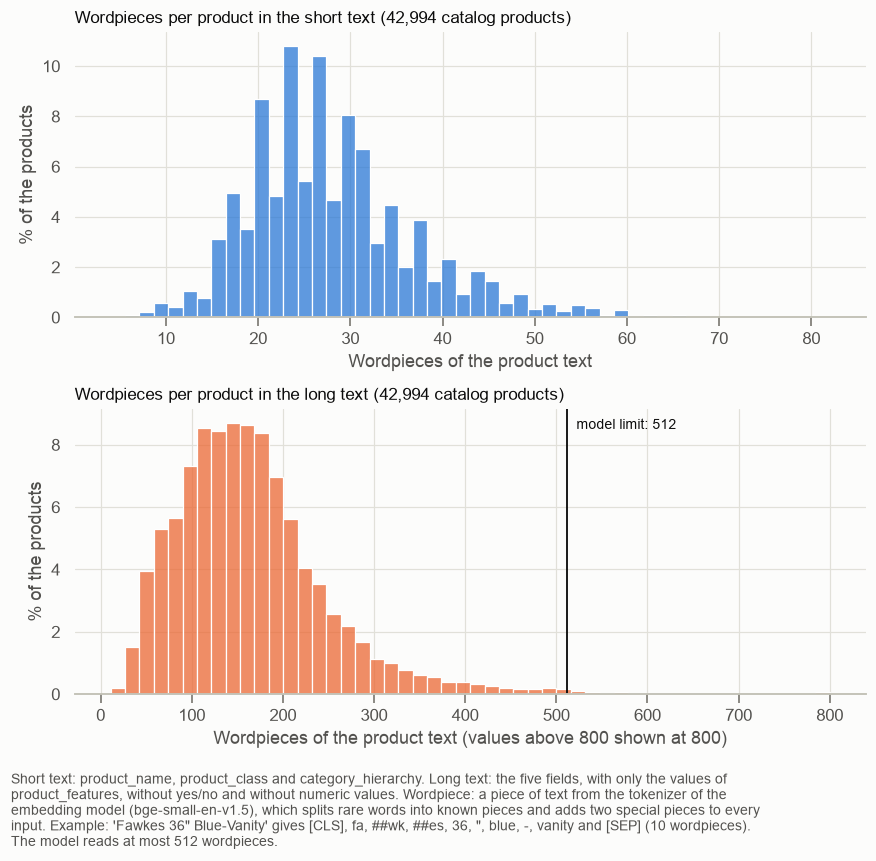

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(8, 7))
for ax, (name, color) in zip(axes, [("short", plots.SERIES_1), ("long", plots.SERIES_2)]):
    sns.histplot(wordpiece_counts[name].clip(upper=800), bins=50, color=color, stat="percent", ax=ax)
    ax.set_title(f"Wordpieces per product in the {name} text ({len(products):,} catalog products)")
    ax.set_xlabel("Wordpieces of the product text" + (" (values above 800 shown at 800)" if name == "long" else ""))
    ax.set_ylabel("% of the products")
plots.reference_line(axes[1], embeddings.MODEL_MAX_WORDPIECES, "model limit: 512")
fig.tight_layout()
plots.add_caption(fig, (
    "Short text: product_name, product_class and category_hierarchy. Long text: the five fields, with only the values "
    "of product_features, without yes/no and without numeric values. " + plots.WORDPIECE_DEFINITION
))
plt.show()

**Resultados**
- **Short text: mediana de 27 wordpieces, p95 de 46 e máximo de 82.** Nenhum produto chega ao limite de 512.
- **Long text: mediana de 154 wordpieces, p95 de 322 e máximo de 1.760.** 238 produtos (0,55% do catalog) passam de 512 e têm o final do texto cortado. Como `product_name` vem primeiro, o corte atinge o fim de `product_description` ou de `product_features`.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Deixar o modelo cortar o long text em 512 wordpieces (0,55% dos produtos) | decidida | dividir o texto em pedaços (chunks), com um embedding por pedaço; pôr `product_features` antes de `product_description` |

## Etapa 2 · Índice e busca

O índice da semantic search (`embeddings.DenseIndex`) guarda o embedding normalizado de cada produto. A busca gera o embedding da query, calcula a cosine similarity com todos os produtos (exact search) e devolve os K de maior score; empates são desfeitos pelo menor `product_id`, como no BM25.

### 2.1 · Custo de indexação

O custo está em gerar os embeddings dos produtos. Medimos o tempo numa amostra de 1.000 produtos do catalog (sem usar o cache), com os textos ordenados por tamanho antes de formar os batches, e estimamos o tempo do catalog inteiro por regra de três. Também medimos a memória dos embeddings.

In [5]:
COST_SAMPLE_SIZE = 1000
SAMPLE_SEED = 0
cost_sample_ids = products["product_id"].sample(COST_SAMPLE_SIZE, random_state=SAMPLE_SEED)

embedding_cost = {}
for name, texts in PRODUCT_TEXTS.items():
    start = time.perf_counter()
    encoder.encode_documents(texts.loc[cost_sample_ids].tolist())
    seconds = time.perf_counter() - start
    embedding_cost[name] = {
        f"seconds for {COST_SAMPLE_SIZE:,} products": seconds,
        "estimated minutes for the catalog": seconds * len(products) / COST_SAMPLE_SIZE / 60,
        "embedding memory (MB)": product_text_indexes[name].index_bytes / 1e6,
    }
plots.table(pd.DataFrame(embedding_cost).T.rename_axis("product text"),
            f"Cost of the product embeddings: time on a sample of {COST_SAMPLE_SIZE:,} products and memory of the catalog",
            note=f"One run on {platform.platform()} ({platform.processor()}), CPU only, batches of {embeddings.BATCH_SIZE} texts "
                 "sorted by length; times change from run to run. Memory: 42,994 embeddings of 384 float32 numbers.")

,"seconds for 1,000 products",estimated minutes for the catalog,embedding memory (MB)
product text,,,
short,6.0,4.3,66.0
long,42.5,30.4,66.0


**Resultados**
- **Na execução salva, os embeddings de 1.000 produtos levaram 6,0 s com o short text e 42,5 s com o long text,** o que dá cerca de 4 e 30 minutos para o catalog inteiro. O long text custa cerca de 7 vezes mais; a razão entre as medianas de wordpieces é 5,7 (Etapa 1.2: 154 contra 27).
- **Os embeddings de cada product text ocupam 66,0 MB em memória** (42.994 × 384 números float32), o dobro dos 33,6 MB do índice do BM25 baseline (`02_bm25_revised.ipynb`, Etapa 2.1).
- **Ler os embeddings dos dois textos do cache levou 0,7 s** (Setup).

**Limitações**
- Uma única execução, numa única máquina, só com CPU; os tempos mudam a cada execução e servem como ordem de grandeza. Com GPU, seriam muito menores.
- A amostra é de 1.000 produtos; a estimativa para o catalog supõe que o resto tem a mesma distribuição de tamanhos.
- O efeito de ordenar os textos por tamanho antes de formar os batches não é medido aqui.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Gerar os embeddings dos produtos no CPU local, uma vez, com cache em disco | decidida | GPU (por exemplo, no Colab), com o mesmo `fastembed` e o mesmo modelo, para que produtos e queries fiquem no mesmo espaço; distribuir o cache para download (planejado antes da entrega) |
| Exact search sobre os 42.994 produtos | decidida | approximate nearest neighbor search (FAISS, HNSW), que só compensa em catalogs muito maiores |

### 2.2 · Entradas inválidas

A semantic search usa as mesmas regras do BM25 (`retrieval.prepare_query`), registradas no `docs/EVALUATION.md`:

| Entrada | Tratamento |
|---|---|
| não é texto (`None`, número, lista) | erro `InvalidQueryError` |
| vazia ou só espaços | erro `InvalidQueryError` |
| sem nenhum token (só caracteres especiais, escrita não latina) | válida: nenhum resultado |
| mais de `MAX_QUERY_CHARS` caracteres | cortada nesse limite; depois, o modelo corta em 512 wordpieces |

Uma diferença em relação ao BM25: uma query com tokens que o catalog não tem (`minnestrista`) **retorna resultados**, porque a semantic search dá um score a todo produto. A tabela roda cada caso, pedindo 100 resultados, no índice do short text sem query prefix (as regras não dependem da combinação).

In [6]:
INVALID_INPUT_CASES = {
    "None": None,
    "number": 42,
    "empty": "",
    "only spaces": "   ",
    "special characters": '&/()"',
    "unknown word": "minnestrista",
    "accents and case": "Décor CHAIR",
    "very long": "leather chair " * 1000,
    "non-latin script": "椅子",
    "emoji": "🪑 chair",
}
input_check_index = semantic_indexes[("short", "no prefix")]
invalid_input_results = []
for case, value in INVALID_INPUT_CASES.items():
    try:
        prepared = retrieval.prepare_query(value)
        results = input_check_index.search(value, k=100)
        invalid_input_results.append({"case": case, "outcome": "ok", "tokens": len(prepared.tokens),
                                      "truncated": prepared.truncated, "results": len(results),
                                      "first result": field_texts.loc[results["product_id"].iloc[0], "product_name"] if len(results) else None})
    except retrieval.InvalidQueryError as error:
        invalid_input_results.append({"case": case, "outcome": f"InvalidQueryError: {error}"})
plots.table(pd.DataFrame(invalid_input_results).set_index("case"), "How the semantic search handles invalid or unusual queries",
            note=f"Limit: {retrieval.MAX_QUERY_CHARS} characters. tokens: tokens of text.tokenize, used only to validate the query; "
                 "the embedding receives the text itself. first result: product_name of the top result. "
                 "null: the query raised an error before the search, or returned nothing.", precision=0)

,outcome,tokens,truncated,results,first result
case,,,,,
None,"InvalidQueryError: query must be a string, got NoneType",null,null,null,null
number,"InvalidQueryError: query must be a string, got int",null,null,null,null
empty,InvalidQueryError: query is empty,null,null,null,null
only spaces,InvalidQueryError: query is empty,null,null,null,null
special characters,ok,0,False,0,null
unknown word,ok,1,False,100,minster tufted storage ottoman
accents and case,ok,2,False,100,style dining chair cushion
very long,ok,32,True,100,leather arm chair in brown
non-latin script,ok,0,False,0,null


**Resultados**
- **Os casos inválidos seguem a regra do BM25:** `None`, número, texto vazio e só espaços geram `InvalidQueryError`; só caracteres especiais e escrita não latina (`椅子`) não têm tokens e retornam 0 resultados, sem erro.
- **Diferente do BM25, `minnestrista` retorna 100 resultados.** O primeiro é `minster tufted storage ottoman`.
- **A query muito longa é cortada em 500 caracteres** (`truncated = True`) e retorna 100 resultados.
- **`Décor CHAIR` e `🪑 chair` retornam produtos, e o primeiro de cada um é uma almofada de cadeira** (`style dining chair cushion` e `chair indoor seat cushion`), não uma cadeira.

**O que isso implica (nossa interpretação)**
- `minnestrista` não tem sentido para o modelo; o primeiro resultado parece vir da escrita parecida (`minster`), e não do significado. Uma query desse tipo recebe produtos sem relação com ela, em vez de nenhum resultado. Na hybrid search, o BM25 não contribui com nada nesse caso, e a lista vem só da semantic search.

**Limitações**
- São casos escolhidos, um de cada tipo; o primeiro resultado de cada um é só ilustração.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Query sem tokens retorna lista vazia, como no BM25 | decidida | gerar o embedding mesmo assim, o que devolveria produtos sem relação com a query |
| Query com tokens desconhecidos retorna resultados | decidida (consequência do método) | um score mínimo de cosine similarity para retornar um produto, que exigiria escolher o corte |

### 2.3 · Latência do retrieval

Tempo de uma busca com K = 100, por query, nas 384 queries do train e do validation set (só o texto, sem `label`), depois de 20 buscas de aquecimento. Separamos as duas partes: gerar o embedding da query e calcular o score dos 42.994 produtos com o corte nos 100 primeiros. Usamos o índice do short text com query prefix; o score custa o mesmo nos dois textos, porque os embeddings têm o mesmo tamanho.

In [7]:
latency_index = semantic_indexes[("short", "bge prefix")]
for query_text in train_validation_queries["query"].head(evaluate.WARMUP_QUERIES):
    latency_index.search(query_text, k=100)

latency_ms = {"query embedding": [], "scores and top 100": []}
for query_text in train_validation_queries["query"]:
    start = time.perf_counter()
    query_vector = latency_index.encoder.encode_query(query_text)
    middle = time.perf_counter()
    latency_index.search_vector(query_vector, 100)
    latency_ms["query embedding"].append((middle - start) * 1000)
    latency_ms["scores and top 100"].append((time.perf_counter() - middle) * 1000)
latency_ms = pd.DataFrame(latency_ms)
latency_ms["total"] = latency_ms.sum(axis=1)

plots.table(latency_ms.quantile([0.5, 0.95, 0.99]).set_axis(["p50", "p95", "p99"]).T.assign(max=latency_ms.max()).rename_axis("part"),
            f"Latency of one semantic search (k = 100), in ms, {len(latency_ms)} train and validation queries",
            note=f"pXX: XXth percentile. One process on {platform.platform()} ({platform.processor()}), CPU only, "
                 f"after {evaluate.WARMUP_QUERIES} warm-up searches.", precision=2)

,p50,p95,p99,max
part,,,,
query embedding,4.67,5.68,6.58,7.79
scores and top 100,2.44,2.74,2.90,3.09
total,7.14,8.24,9.00,10.18


**Resultados**
- **Na execução salva, uma semantic search leva 7,1 ms no p50 e 8,2 ms no p95** (máximo de 10,2 ms), nas 384 queries do train e do validation set.
- **Dois terços desse tempo são o embedding da query:** 4,7 ms no p50. O score dos 42.994 produtos e o corte nos 100 primeiros levam 2,4 ms.

**O que isso implica (nossa interpretação)**
- A hybrid search roda as duas buscas, então a latência dela fica perto da soma das duas (na execução salva de `02_bm25_revised.ipynb`, Etapa 2.4, o BM25 baseline levou 1,4 ms no p50). Continua baixa para o sistema completo.

**Limitações**
- Medido num único processo, numa única máquina, só com CPU, uma query por vez; os valores mudam a cada execução e com o hardware. Uma única execução não mostra se um sistema é mais rápido que outro.

## Etapa 3 · Tuning da semantic search no train set

### 3.1 · A grade

A grade foi fixada antes de rodar (`docs/EVALUATION.md`): **product text** (short ou long) × **query prefix** (sem ou com a instrução do bge), 4 combinações, nas 287 queries do train set. O embedding model não aprende com os `label`, então, como no tuning do BM25, os `label` do train set só servem para comparar as combinações.

**Regra de escolha:** a mesma do BM25. Fica a combinação de maior Capped Recall@100 (só Exact); se a diferença para a melhor for menor que 0,005, desempata o NDCG@10. A semantic search vai gerar candidatos para o reranker (sozinha ou na hybrid search), então o que importa é trazer os Exact para os 100 primeiros.

O resultado da combinação escolhida no train set é otimista (é a melhor entre 4) e não entra na comparação entre sistemas.

In [8]:
METRICS = ["ndcg@10", "mrr@10", "capped_recall@50", "capped_recall@100", "capped_recall@200", "judged@10", "condensed_ndcg@10"]


def combination_name(text_name: str, prefix_name: str) -> str:
    return f"{text_name} text, {prefix_name}"


def search_function(index):
    """Search function of evaluate: query text and K in, product_ids in rank order out."""
    return lambda query_text, k: index.search(query_text, k=k)["product_id"].tolist()


semantic_grid = {combination_name(*key): search_function(index) for key, index in semantic_indexes.items()}
start = time.perf_counter()
semantic_tuning, semantic_tuning_per_query = evaluate.evaluate_grid(semantic_grid, train_queries, labels_by_query)
print(f"grid of {len(semantic_tuning)} combinations in {time.perf_counter() - start:.0f} s")

display(plots.table(semantic_tuning.set_index("system")[METRICS].rename_axis("combination"),
                    "Semantic search tuning: mean of each metric on the 287 train queries",
                    note="MRR@10 and Capped Recall: Exact only, 227 train queries with Exact. bge prefix: the query starts with "
                         "'Represent this sentence for searching relevant passages: '.", precision=3))
semantic_chosen = evaluate.select_tuned(semantic_tuning)
print(f"chosen: {semantic_chosen['system']} | train capped_recall@100 = {semantic_chosen['capped_recall@100']:.3f}, "
      f"ndcg@10 = {semantic_chosen['ndcg@10']:.3f}")

grid of 4 combinations in 8 s


,ndcg@10,mrr@10,capped_recall@50,capped_recall@100,capped_recall@200,judged@10,condensed_ndcg@10
combination,,,,,,,
"short text, no prefix",0.716,0.689,0.616,0.671,0.741,0.822,0.828
"short text, bge prefix",0.724,0.712,0.628,0.680,0.746,0.829,0.833
"long text, no prefix",0.738,0.703,0.642,0.699,0.760,0.828,0.850
"long text, bge prefix",0.739,0.723,0.653,0.708,0.773,0.828,0.853


chosen: long text, bge prefix | train capped_recall@100 = 0.708, ndcg@10 = 0.739


As diferenças da grade são maiores que o ruído da amostra de queries? Comparamos cada combinação com a escolhida, query a query, com o paired bootstrap (diferença = combinação − escolhida, intervalo de 95%, train set).

In [9]:
semantic_grid_differences = []
for name, per_query in semantic_tuning_per_query.items():
    if name == semantic_chosen["system"]:
        continue
    row = {"combination": name}
    for metric in ["capped_recall@100", "ndcg@10"]:
        difference = evaluate.paired_bootstrap(per_query, semantic_tuning_per_query[semantic_chosen["system"]], metric)
        row[f"{metric} difference [95% CI]"] = evaluate.format_ci(difference["mean_difference"], difference["ci_low"], difference["ci_high"])
        row[f"{metric} excludes 0"] = difference["ci_low"] > 0 or difference["ci_high"] < 0
    semantic_grid_differences.append(row)
plots.table(pd.DataFrame(semantic_grid_differences).set_index("combination"),
            f"Semantic search tuning: each combination minus the chosen one ({semantic_chosen['system']}), train set",
            note="Mean paired difference with 95% paired bootstrap interval. excludes 0: the interval does not contain 0.")

,capped_recall@100 difference [95% CI],capped_recall@100 excludes 0,ndcg@10 difference [95% CI],ndcg@10 excludes 0
combination,,,,
"short text, no prefix",-0.037 [-0.063; -0.012],True,-0.023 [-0.044; -0.003],True
"short text, bge prefix",-0.028 [-0.052; -0.001],True,-0.015 [-0.034; 0.003],False
"long text, no prefix",-0.009 [-0.018; -0.000],True,-0.001 [-0.012; 0.010],False


**Resultados**
- **Combinação escolhida: long text com bge prefix,** com Capped Recall@100 de 0,708 e NDCG@10 de 0,739 no train set. Nenhuma outra ficou a menos de 0,005 dela em Capped Recall@100 (a segunda tem 0,699), então o desempate pelo NDCG@10 não foi usado. Ela tem o maior valor em todas as métricas da tabela, menos judged@10 (0,828, contra 0,829 do short text com bge prefix).
- **O long text traz mais Exact para os 100 primeiros que o short text:** contra a escolhida, o short text tem Capped Recall@100 menor sem prefix (−0,037 [−0,063; −0,012]) e com prefix (−0,028 [−0,052; −0,001]), os dois com intervalo que exclui 0.
- **O bge prefix ajuda pouco:** no long text, sem prefix o Capped Recall@100 é 0,009 menor, com intervalo que exclui 0 por pouco ([−0,018; −0,000]), e o NDCG@10 não muda (−0,001 [−0,012; 0,010]).
- Na execução salva, a grade levou 9 s, porque os embeddings dos produtos vêm do cache e só os das queries são gerados.

**O que isso implica (nossa interpretação)**
- Para este embedding model, a informação de `product_description` e `product_features` ajuda mais do que atrapalha, embora o vetor passe a resumir um texto 5,7 vezes maior (Etapa 1.2).

**Limitações**
- O resultado da combinação escolhida no train set é otimista (a melhor entre 4) e serve só para escolher.
- Os intervalos não corrigem para 3 comparações.
- Só um embedding model foi testado.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Semantic search com long text e bge prefix, pela regra registrada no `docs/EVALUATION.md` | decidida | short text; sem prefix; um embedding por field; outro embedding model (`all-MiniLM-L6-v2`, `bge-base-en-v1.5`); fine-tuning |

### 3.2 · Referência: a combinação escolhida e a BM25 v2 no train set

Só para ter uma ordem de grandeza antes do validation set: a combinação escolhida contra a BM25 v2, nas mesmas 287 queries do train set. **Não é a comparação entre sistemas:** as duas foram escolhidas nessas queries (a BM25 v2 entre 20 combinações de `k1` e `b`, a semantic search entre 4), então os dois valores são otimistas. A comparação vale no validation set, na próxima etapa.

In [10]:
def v2_search(query_text: str, k: int) -> list[int]:
    return v2_index.search(query_text, k=k)["product_id"].tolist()


_, v2_train = evaluate.evaluate_grid({"BM25 v2": v2_search}, train_queries, labels_by_query)
v2_train_per_query = v2_train["BM25 v2"]
semantic_train_per_query = semantic_tuning_per_query[semantic_chosen["system"]]
semantic_vs_v2_train = evaluate.compare_systems(semantic_train_per_query, v2_train_per_query, METRICS, name_a="semantic", name_b="v2")
plots.table(semantic_vs_v2_train[["v2_ci", "semantic_ci", "difference_ci", "interval_excludes_0", "n_queries",
                                  "share_semantic_better", "share_v2_better"]],
            f"Reference only: semantic search ({semantic_chosen['system']}) vs BM25 v2 on the train set",
            note="Both were chosen on these queries, so both values are optimistic. *_ci: mean with 95% bootstrap interval. "
                 "difference_ci: mean paired difference semantic - v2. share_*_better: share of queries where that system scores higher.",
            precision=3)

,v2_ci,semantic_ci,difference_ci,interval_excludes_0,n_queries,share_semantic_better,share_v2_better
ndcg@10,0.721 [0.688; 0.755],0.739 [0.707; 0.772],0.018 [-0.006; 0.040],False,287,0.397,0.369
mrr@10,0.725 [0.671; 0.777],0.723 [0.671; 0.771],-0.002 [-0.046; 0.043],False,227,0.194,0.159
capped_recall@50,0.657 [0.612; 0.700],0.653 [0.611; 0.695],-0.004 [-0.034; 0.028],False,227,0.317,0.348
capped_recall@100,0.731 [0.691; 0.770],0.708 [0.669; 0.747],-0.023 [-0.050; 0.004],False,227,0.256,0.366
capped_recall@200,0.795 [0.759; 0.832],0.773 [0.738; 0.810],-0.022 [-0.050; 0.004],False,227,0.247,0.361
judged@10,0.821 [0.789; 0.854],0.828 [0.795; 0.860],0.007 [-0.015; 0.029],False,287,0.233,0.233
condensed_ndcg@10,0.840 [0.814; 0.865],0.853 [0.830; 0.875],0.013 [-0.006; 0.032],False,287,0.331,0.289


**Resultados**
- **No train set, a semantic search não se distingue da BM25 v2 em nenhuma métrica:** todos os intervalos incluem 0. NDCG@10 de 0,739 contra 0,721 (+0,018 [−0,006; 0,040]); Capped Recall@100 de 0,708 contra 0,731 (−0,023 [−0,050; 0,004]).
- **Os dois sistemas acertam em queries diferentes:** em Capped Recall@100, a semantic search é melhor em 25,6% das 227 queries com Exact e a BM25 v2 em 36,6%; em NDCG@10, 39,7% e 36,9% das 287 queries.
- **judged@10 é parecido nos dois** (0,828 e 0,821, +0,007 [−0,015; 0,029]). No train set, a semantic search não traz mais produtos sem `label` para o topo, ao contrário do risco que o `docs/EVALUATION.md` antecipava.
- Os valores da BM25 v2 (NDCG@10 de 0,721 e Capped Recall@100 de 0,731) são os mesmos do tuning em `02_bm25_revised.ipynb`, Etapa 4.2.

**O que isso implica (nossa interpretação)**
- Se cada sistema traz Exact que o outro perde, a hybrid search pode cobrir mais que os dois sozinhos. As frações de queries não dizem quanto a mais; a próxima etapa mede no validation set.

**Limitações**
- Os dois valores são otimistas (cada sistema foi escolhido nessas queries) e servem só como ordem de grandeza. A comparação entre sistemas é a do validation set.

### 3.3 · Três exemplos do train set

Os 10 primeiros resultados da combinação escolhida para três queries do **train set**, com o `label` de cada produto (`no label` = o produto não foi julgado para a query), e quantos dos 10 primeiros de cada sistema têm cada `label`:
- `tye dye duvet cover` e `pedistole sink`: têm um token que não existe no catalog (`tye`, e o typo `pedistole`), o que limita o BM25 (`02_bm25_revised.ipynb`, Etapa 2.2);
- `bed side table`: tem 81 Exact e NDCG@10 = 0 no BM25 baseline; a hipótese da error analysis de `02_bm25_revised.ipynb` (Etapa 3.4) é que os Exact usam outras palavras, como `bedside` ou `nightstand`.

In [11]:
EXAMPLE_QUERIES = ["tye dye duvet cover", "pedistole sink", "bed side table"]
chosen_index = semantic_indexes[tuple(key for key in semantic_indexes if combination_name(*key) == semantic_chosen["system"])[0]]


def top_results_with_labels(index, query_text: str, k: int = 10) -> pd.DataFrame:
    """Top k results of a train query, with the label of each product and its product_name."""
    query_id = train_queries.loc[train_queries["query"] == query_text, "query_id"].iloc[0]
    results = index.search(query_text, k=k)
    results["label"] = results["product_id"].map(labels_by_query[query_id]).fillna("no label")
    results["product_name"] = field_texts.loc[results["product_id"], "product_name"].to_numpy()
    return results.set_index("rank")


label_counts = {}
for query_text in EXAMPLE_QUERIES:
    semantic_top = top_results_with_labels(chosen_index, query_text)
    display(plots.table(semantic_top, f"Top 10 semantic search results ({semantic_chosen['system']}) for the train query '{query_text}'",
                        note="score: cosine similarity between the query embedding and the product embedding.", precision=3))
    for system, top in [("semantic", semantic_top), ("BM25 v2", top_results_with_labels(v2_index, query_text))]:
        label_counts[(query_text, system)] = top["label"].value_counts()
plots.table(pd.DataFrame(label_counts).T.reindex(columns=["Exact", "Partial", "Irrelevant", "no label"]).fillna(0).astype(int)
            .rename_axis(["query", "system"]),
            "Labels among the top 10 results of each system, for the three train queries")

,product_id,score,label,product_name
rank,,,,
1,"11,625",0.794,no label,mirror dye duvet cover
2,"11,754",0.790,no label,jacqueline maldonado mirror dye stone duvet cover
3,"17,332",0.789,Exact,tangerine tie dye by laura trevey lightweight duvet cover
4,"27,833",0.786,no label,tie dye tribal stylized trippy shapes with dirt grungy paint reflections artisan print duvet cover set
5,"11,777",0.785,no label,jacqueline maldonado mirror dye single duvet cover
6,"27,837",0.784,Exact,tie dye spiritual ikat with hallucinatory concentric fractal weird creepy reflection duvet cover set
7,"27,834",0.778,no label,tie dye distressed background with pleating gradient brushed marble effect image duvet cover set
8,"38,312",0.777,no label,single reversible duvet cover
9,"12,063",0.776,Partial,caldello peacock duvet cover set


,product_id,score,label,product_name
rank,,,,
1,"2,390",0.726,no label,venice rectangular vessel bathroom sink
2,"13,653",0.723,no label,marlie 36 '' single bathroom vanity set
3,"35,464",0.722,no label,larochelle jora 24 '' single bathroom vanity set
4,"28,689",0.721,no label,gidney 47 '' single bathroom vanity set
5,"19,673",0.720,Partial,edrian 35 '' single sink bathroom vanity set
6,"7,120",0.719,no label,laverne 36 '' single bathroom vanity set
7,"10,944",0.719,no label,black ceramic rectangular vessel bathroom sink
8,"37,899",0.718,no label,vigo matte stone™ rectangular vessel bathroom sink
9,"31,194",0.717,no label,la finese 41 '' single vanity set


,product_id,score,label,product_name
rank,,,,
1,"37,335",0.798,no label,opperman end table
2,"42,303",0.797,no label,plain end table
3,"20,503",0.793,Partial,butner end table
4,"28,420",0.791,no label,bluxome end table
5,"17,123",0.790,no label,tilden end table with storage
6,"20,504",0.789,no label,butner end table
7,"31,043",0.789,no label,seo solid wood end table with storage
8,"13,886",0.788,no label,cueto tray top end table
9,"17,597",0.787,no label,alixis end table with storage


**Resultados**
- **`tye dye duvet cover`:** a semantic search encontra produtos de *tie dye* (3 Exact entre os 10 primeiros), mas as posições 1, 2 e 5 são de *mirror dye*, sem `label`. A BM25 v2 tem 4 Exact e 2 Partial. São 6 produtos sem `label` nos 10 primeiros da semantic search, contra 4 na BM25 v2.
- **`pedistole sink`:** a semantic search traz pias e vanity sets de banheiro, nenhum com *pedestal* no `product_name`: 1 Partial e 9 sem `label`. A BM25 v2 tem 2 Partial e 8 sem `label`; nenhum dos dois traz um Exact.
- **`bed side table`:** os 10 primeiros da semantic search são `end table`s (1 Partial, 9 sem `label`), e nenhum `nightstand`. A BM25 v2 também não tem Exact (1 Partial, 9 sem `label`).

**Limitações**
- São três queries escolhidas por serem difíceis para o BM25, não uma amostra. As métricas das 287 queries estão nas Etapas 3.1 e 3.2.

**Hipóteses para a error analysis (não conferidas)**
- Produtos sem `label` com cara de relevantes: em `tye dye duvet cover`, as posições 4 e 7 têm *tie dye duvet cover* no `product_name` e não têm `label`. O NDCG@10 conta esses produtos como 0.
- O embedding de uma palavra com erro (`tye`, `pedistole`) parece ficar perto de palavras de escrita parecida (`mirror dye`), e não da palavra certa.
- Em `bed side table`, o modelo aproxima a query de *end table*, e não de *nightstand*; a hipótese de `02_bm25_revised.ipynb` (Etapa 3.4), de que os Exact usam `nightstand`, não foi conferida.

## Etapa 4 · A semantic search no validation set, contra a BM25 v2

Rodamos uma única vez, nas 97 queries do validation set, a combinação escolhida no train set na Etapa 3.1 (long text com bge prefix), e a comparamos com a BM25 v2 (`k1 = 1.2`, `b = 0.5`; NDCG@10 de 0,653 no validation set em `02_bm25_revised.ipynb`, Etapa 4.3). As duas rodam pelo mesmo procedimento, `evaluate.evaluate_system`: cada busca pede os 200 primeiros, depois de 20 buscas de aquecimento, e a latência é a desse pedido.

A comparação usa o paired bootstrap (diferença = semantic search − BM25 v2, intervalo de 95%). Duas regras do `docs/EVALUATION.md` dependem dela:
- a seleção final entre sistemas é pelo NDCG@10, preferindo o mais simples (a BM25 v2) quando o intervalo da diferença inclui 0;
- o retrieval que fornece os candidatos do reranker é o de maior Capped Recall@100, com a mesma preferência pelo mais simples. Essa escolha só é feita depois da hybrid search (Etapa 5).

Também conferimos a pendência do protocolo sobre os produtos sem `label`: se a regra "produto sem `label` = gain 0" muda a comparação, olhando judged@10 e condensed NDCG@10 dos dois sistemas.

### 4.1 · Métricas e latência

In [12]:
semantic_search = search_function(chosen_index)
semantic_validation_per_query = evaluate.evaluate_system(semantic_search, validation_queries, labels_by_query)
v2_validation_per_query = evaluate.evaluate_system(v2_search, validation_queries, labels_by_query)

semantic_vs_v2 = evaluate.compare_systems(semantic_validation_per_query, v2_validation_per_query, METRICS,
                                          name_a="semantic", name_b="v2")
display(plots.table(semantic_vs_v2[["v2_ci", "semantic_ci", "difference_ci", "interval_excludes_0", "n_queries",
                                    "share_semantic_better", "share_v2_better"]],
                    f"Semantic search ({semantic_chosen['system']}) vs BM25 v2 on the validation set",
                    note="*_ci: mean with 95% bootstrap interval. difference_ci: mean paired difference semantic - v2, with 95% interval. "
                         "share_*_better: share of queries where that system scores higher. MRR@10 and Capped Recall: Exact only.",
                    precision=3))
plots.table(pd.DataFrame({
    system: per_query["latency_ms"].quantile([0.5, 0.95]).set_axis(["latency_ms_p50", "latency_ms_p95"])
    for system, per_query in [("BM25 v2", v2_validation_per_query), ("semantic", semantic_validation_per_query)]
}), "Latency of one search (k = 200), validation set: BM25 v2 vs semantic search", precision=2,
    note=f"One process on {platform.platform()} ({platform.processor()}), CPU only, after {evaluate.WARMUP_QUERIES} warm-up searches.")

,v2_ci,semantic_ci,difference_ci,interval_excludes_0,n_queries,share_semantic_better,share_v2_better
ndcg@10,0.653 [0.589; 0.718],0.725 [0.668; 0.785],0.072 [0.029; 0.116],True,97,0.495,0.289
mrr@10,0.661 [0.564; 0.752],0.661 [0.565; 0.752],0.000 [-0.066; 0.070],False,77,0.156,0.182
capped_recall@50,0.651 [0.572; 0.730],0.634 [0.553; 0.710],-0.018 [-0.063; 0.031],False,77,0.260,0.377
capped_recall@100,0.705 [0.628; 0.778],0.678 [0.601; 0.751],-0.027 [-0.068; 0.017],False,77,0.208,0.403
capped_recall@200,0.786 [0.715; 0.851],0.761 [0.690; 0.821],-0.025 [-0.071; 0.023],False,77,0.182,0.429
judged@10,0.782 [0.719; 0.839],0.824 [0.770; 0.874],0.050 [0.006; 0.099],True,96,0.312,0.219
condensed_ndcg@10,0.799 [0.749; 0.851],0.836 [0.792; 0.878],0.037 [0.006; 0.070],True,97,0.340,0.299


,BM25 v2,semantic
latency_ms_p50,0.94,7.84
latency_ms_p95,3.40,8.58


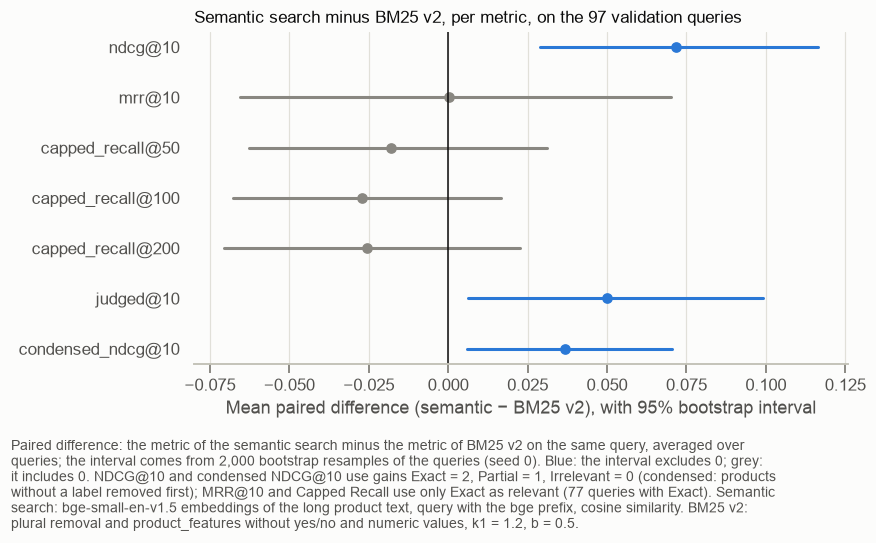

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
plots.difference_plot(ax, list(semantic_vs_v2.index), semantic_vs_v2["difference"],
                      semantic_vs_v2["difference_ci_low"], semantic_vs_v2["difference_ci_high"])
ax.set_title("Semantic search minus BM25 v2, per metric, on the 97 validation queries")
ax.set_xlabel("Mean paired difference (semantic − BM25 v2), with 95% bootstrap interval")
fig.tight_layout()
plots.add_caption(fig, (
    "Paired difference: the metric of the semantic search minus the metric of BM25 v2 on the same query, averaged over "
    "queries; the interval comes from 2,000 bootstrap resamples of the queries (seed 0). Blue: the interval excludes 0; "
    "grey: it includes 0. NDCG@10 and condensed NDCG@10 use gains Exact = 2, Partial = 1, Irrelevant = 0 (condensed: "
    "products without a label removed first); MRR@10 and Capped Recall use only Exact as relevant (77 queries with Exact). "
    "Semantic search: bge-small-en-v1.5 embeddings of the long product text, query with the bge prefix, cosine similarity. "
    "BM25 v2: plural removal and product_features without yes/no and numeric values, k1 = 1.2, b = 0.5."
))
plt.show()

**Resultados**
- **A semantic search tem NDCG@10 maior no validation set: 0,725, contra 0,653 da BM25 v2 (+0,072 [0,029; 0,116]),** com intervalo acima de 0. O NDCG@10 melhora em 49,5% das queries e piora em 28,9%.
- **O MRR@10 não muda:** 0,661 nos dois (0,000 [−0,066; 0,070]).
- **A semantic search não traz mais Exact para os candidatos:** Capped Recall@100 de 0,678, contra 0,705 (−0,027 [−0,068; 0,017]); em @50 e @200, os intervalos também incluem 0. Em Capped Recall@100, a BM25 v2 é melhor em 40,3% das 77 queries com Exact, e a semantic search em 20,8%.
- **A semantic search traz mais produtos julgados para o topo, e não menos:** judged@10 de 0,824, contra 0,782 (+0,050 [0,006; 0,099]). O condensed NDCG@10 também fica à frente (+0,037 [0,006; 0,070]). A regra "produto sem `label` = gain 0" não inverte a comparação: a semantic search fica à frente nas duas versões do NDCG@10.
- **Na execução salva, a latência é de 0,94 ms (p50) e 3,40 ms (p95) na BM25 v2, e de 7,84 ms e 8,58 ms na semantic search.**

**O que isso implica (nossa interpretação)**
- Pela regra da seleção final (NDCG@10), a semantic search fica à frente da BM25 v2. A seleção só é feita depois de todos os sistemas medidos.
- Pela regra do retrieval que fornece os candidatos do reranker (Capped Recall@100), a semantic search não supera a BM25 v2, e entre as duas ficaria a mais simples, a BM25 v2. Essa escolha espera a hybrid search.
- A semantic search ordena melhor os 10 primeiros, mas não cobre mais Exact entre os 100. Para o sistema com reranker, o que conta é a cobertura; a ordem do topo é trabalho do reranker.

**Limitações**
- Só 77 queries do validation set têm Exact, então os intervalos do Capped Recall e do MRR@10 são largos.
- judged@10 tem 96 queries no paired bootstrap: `minnestrista` não tem resultado na BM25 v2, e judged@10 não é definido para lista vazia.
- A latência é de uma execução, numa máquina, só com CPU; a diferença de ordem de grandeza (cerca de 1 ms contra 8 ms) é a parte estável, e vem do embedding da query (Etapa 2.3).

### 4.2 · Onde está o ganho de NDCG@10

Na Etapa 4.1, o NDCG@10 melhora e o MRR@10 não muda. O MRR@10 conta só Exact, e o NDCG@10 conta também Partial (gain 1). Separamos as 97 queries do validation set em dois grupos, as 77 com algum Exact e as 20 sem nenhum Exact (só Partial e Irrelevant), e calculamos a diferença de NDCG@10 em cada grupo, com o paired bootstrap.

Depois, as 5 queries em que a semantic search mais ganha e as 5 em que mais perde no NDCG@10, contra a BM25 v2, com o Capped Recall@100 e o judged@10 de cada sistema. Servem para a error analysis e para entender o que a hybrid search pode combinar.

In [14]:
query_has_exact = v2_validation_per_query["mrr@10"].notna()
ndcg_by_group = []
for group_name, in_group in [("queries with Exact", query_has_exact), ("queries without Exact", ~query_has_exact)]:
    difference = evaluate.paired_bootstrap(semantic_validation_per_query[in_group], v2_validation_per_query[in_group], "ndcg@10")
    ndcg_by_group.append({
        "group": group_name,
        "queries": difference["n_queries"],
        "ndcg@10 v2": v2_validation_per_query.loc[in_group, "ndcg@10"].mean(),
        "ndcg@10 semantic": semantic_validation_per_query.loc[in_group, "ndcg@10"].mean(),
        "difference [95% CI]": evaluate.format_ci(difference["mean_difference"], difference["ci_low"], difference["ci_high"]),
    })
plots.table(pd.DataFrame(ndcg_by_group).set_index("group"),
            "NDCG@10 of the semantic search and BM25 v2 on the validation set, by whether the query has an Exact product",
            note="difference: mean paired difference semantic - v2, with 95% paired bootstrap interval. "
                 "Queries without Exact have only Partial and Irrelevant products.", precision=3)

,queries,ndcg@10 v2,ndcg@10 semantic,difference [95% CI]
group,,,,
queries with Exact,77,0.681,0.736,0.056 [0.018; 0.096]
queries without Exact,20,0.546,0.679,0.133 [-0.019; 0.282]


In [15]:
query_differences = pd.DataFrame({
    "query": validation_queries.set_index("query_id")["query"],
    "ndcg@10 v2": v2_validation_per_query["ndcg@10"],
    "ndcg@10 semantic": semantic_validation_per_query["ndcg@10"],
    "capped_recall@100 v2": v2_validation_per_query["capped_recall@100"],
    "capped_recall@100 semantic": semantic_validation_per_query["capped_recall@100"],
    "judged@10 v2": v2_validation_per_query["judged@10"],
    "judged@10 semantic": semantic_validation_per_query["judged@10"],
})
query_differences["ndcg@10 difference"] = query_differences["ndcg@10 semantic"] - query_differences["ndcg@10 v2"]
for title, rows in [("largest gains", query_differences.nlargest(5, "ndcg@10 difference")),
                    ("largest losses", query_differences.nsmallest(5, "ndcg@10 difference"))]:
    display(plots.table(rows, f"Validation queries with the {title} of the semantic search over BM25 v2 in NDCG@10",
                        note="ndcg@10 difference: semantic - v2. null: Capped Recall is not defined for queries without Exact, "
                             "and judged@10 for an empty result list.", precision=3))

,query,ndcg@10 v2,ndcg@10 semantic,capped_recall@100 v2,capped_recall@100 semantic,judged@10 v2,judged@10 semantic,ndcg@10 difference
query_id,,,,,,,,
362,brushed gold wall decor,0.066,0.922,null,null,0.100,0.900,0.855
202,full mattress padded liner,0.000,0.820,0.156,0.733,0.000,0.800,0.820
269,donaldson teak couch,0.287,0.936,null,null,0.300,0.900,0.650
458,bubble guppies chair,0.373,0.934,null,null,0.900,1.000,0.561
375,pastel pink desk chair,0.332,0.855,null,null,0.400,0.800,0.523


,query,ndcg@10 v2,ndcg@10 semantic,capped_recall@100 v2,capped_recall@100 semantic,judged@10 v2,judged@10 semantic,ndcg@10 difference
query_id,,,,,,,,
219,trinaic towel rod,1.000,0.402,null,null,1.000,0.500,-0.598
98,gracie oaks 62 oller 14 ceiling fan,1.000,0.670,null,null,1.000,0.800,-0.330
451,aiden black velvet bed,0.792,0.470,null,null,0.700,0.600,-0.322
186,board game storage cabinet,0.887,0.582,1.000,1.000,0.900,0.600,-0.305
425,side table with storage,0.813,0.549,0.500,0.357,1.000,0.900,-0.264


**Resultados**
- **O ganho de NDCG@10 aparece nas queries com Exact:** +0,056 [0,018; 0,096] nas 77 queries com Exact (0,736 contra 0,681). Nas 20 sem Exact, a diferença é maior (+0,133), mas com intervalo largo que inclui 0 ([−0,019; 0,282]).
- **As maiores perdas da semantic search incluem três queries com nome próprio de produto ou marca:** `trinaic towel rod` (−0,598), `gracie oaks 62 oller 14 ceiling fan` (−0,330) e `aiden black velvet bed` (−0,322), com NDCG@10 de 1,000, 1,000 e 0,792 na BM25 v2. As outras duas são descritivas: `board game storage cabinet` e `side table with storage`.
- **Os maiores ganhos são, na maioria, queries descritivas:** `brushed gold wall decor` (+0,855), `full mattress padded liner` (+0,820), `pastel pink desk chair` (+0,523), além de `donaldson teak couch` (+0,650; `donaldson` não existe no catalog, `02_bm25_revised.ipynb` Etapa 1.4) e `bubble guppies chair` (+0,561).
- **Em 4 dos 5 maiores ganhos, a BM25 v2 tinha poucos produtos julgados no topo** (judged@10 de 0,000 a 0,400); na semantic search, de 0,800 a 0,900.

**O que isso implica (nossa interpretação)**
- Como o MRR@10 não muda (Etapa 4.1), o ganho nas queries com Exact parece vir dos produtos abaixo do primeiro Exact: mais Exact e Partial nas posições 2 a 10.
- A BM25 v2 acerta quando a query tem um nome raro que aparece igual no `product_name`; a semantic search acerta quando a query descreve o produto com palavras diferentes das do catalog. São erros diferentes, o que é o argumento para a hybrid search.

**Limitações**
- As 10 queries foram escolhidas pela maior diferença, então mostram os casos extremos, não os típicos.
- O grupo sem Exact tem só 20 queries.

**Hipóteses para a error analysis (não conferidas)**
- Nomes próprios raros (`trinaic`, `oller`) viram vários wordpieces, e o embedding perde a identidade do nome, que o BM25 encontra por igualdade de token.
- Nos ganhos em que a BM25 v2 tinha judged@10 baixo, parte da diferença pode vir de produtos relevantes sem `label` no topo da BM25 v2.

## Etapa 5 · Hybrid search: diagnóstico e peso de cada lista no train set

A hybrid search junta a lista da BM25 v2 e a da semantic search com **weighted RRF**: cada produto recebe w / (60 + posição na BM25 v2) + (1 − w) / (60 + posição na semantic search), e a nova ordem segue essa soma. Um produto ausente de uma lista não recebe nada dela. Cada lista entra com os seus 200 primeiros (`retrieval.RRF_DEPTH`).

Usamos a posição, e não o score, porque os scores estão em escalas diferentes: o da BM25 não tem limite (por exemplo, 3 ou 25), e a cosine similarity dos primeiros resultados fica perto de 0,7 a 0,8 (Etapa 3.3). Somar os scores deixaria a BM25 decidir quase tudo.

O peso w foi registrado no `docs/EVALUATION.md` antes de rodar: primeiro uma grade só de w, com k = 60 (Etapa 5.2), depois substituída por uma grade conjunta de k e w (Etapa 5.3), que dá a escolha final. A grade de w é {0,2; 0,35; 0,5; 0,65; 0,8}, no train set, com a mesma regra de escolha das Etapas 3.1 e da BM25. O motivo: na Etapa 4.1, a BM25 v2 tem o maior Capped Recall@100 e a semantic search o maior NDCG@10, então o peso igual (w = 0,5, o RRF padrão) pode não ser o melhor.

### 5.1 · Diagnóstico: quanto as duas listas se sobrepõem, e o teto da union

Antes de escolher w, medimos no train set, por query:
- o **overlap@100:** quantos dos 100 primeiros da BM25 v2 também estão nos 100 primeiros da semantic search;
- o **teto de Capped Recall@100 da union:** min(Exact na union, 100) ÷ min(100, Exact da query) (`metrics.union_capped_recall_at_k`). Nenhuma fusão que entregue 100 produtos tirados da union passa desse valor. Calculamos com a union dos 100 primeiros e com a dos 200 primeiros, que é o que o RRF recebe.

Para isso, guardamos os 200 primeiros de cada sistema para cada query do train set; a grade da Etapa 5.2 reaproveita essas listas.

In [16]:
FUSION_DEPTH = retrieval.RRF_DEPTH
train_lists = {
    query_text: (v2_index.search(query_text, k=FUSION_DEPTH)["product_id"].tolist(),
                 chosen_index.search(query_text, k=FUSION_DEPTH)["product_id"].tolist())
    for query_text in train_queries["query"]
}
assert len(train_lists) == len(train_queries), "train query texts must be unique to key the stored lists"

union_diagnostic = []
for query_id, query_text in zip(train_queries["query_id"], train_queries["query"]):
    v2_ids, semantic_ids = train_lists[query_text]
    query_labels = labels_by_query.get(query_id, {})
    union_diagnostic.append({
        "query_id": query_id,
        "overlap@100": len(set(v2_ids[:100]) & set(semantic_ids[:100])),
        "capped_recall@100 v2": metrics.capped_recall_at_k(v2_ids, query_labels, k=100),
        "capped_recall@100 semantic": metrics.capped_recall_at_k(semantic_ids, query_labels, k=100),
        "union ceiling, top 100 of each": metrics.union_capped_recall_at_k([v2_ids, semantic_ids], query_labels, k=100, depth=100),
        "union ceiling, top 200 of each": metrics.union_capped_recall_at_k([v2_ids, semantic_ids], query_labels, k=100, depth=FUSION_DEPTH),
    })
union_diagnostic = pd.DataFrame(union_diagnostic).set_index("query_id")

display(plots.table(evaluate.summary_table(union_diagnostic)[["mean", "ci_low", "ci_high", "n_queries"]],
                    "Overlap of the top 100 of BM25 v2 and the semantic search, and Capped Recall@100 of each list and of their union, train set",
                    note="overlap@100: products in the top 100 of both systems (0 to 100). union ceiling: min(Exact in the union, 100) / "
                         "min(100, Exact of the query), the best Capped Recall@100 of any 100 products taken from the union. "
                         "Capped Recall: Exact only, 227 train queries with Exact. ci_low and ci_high: 95% bootstrap interval.",
                    precision=3))
v2_recall = union_diagnostic[["capped_recall@100 v2"]].set_axis(["capped_recall@100"], axis=1)
ceiling_gain = pd.DataFrame({
    name: evaluate.paired_bootstrap(union_diagnostic[[name]].set_axis(["capped_recall@100"], axis=1), v2_recall, "capped_recall@100")
    for name in ["union ceiling, top 100 of each", "union ceiling, top 200 of each"]
}).T[["mean_difference", "ci_low", "ci_high", "n_queries", "share_a_better"]].rename(columns={"share_a_better": "share of queries above v2"})
plots.table(ceiling_gain, "Union ceiling minus Capped Recall@100 of BM25 v2 alone, train set",
            note="Mean paired difference with 95% paired bootstrap interval, over the train queries with Exact.", precision=3)

,mean,ci_low,ci_high,n_queries
overlap@100,46.899,44.157,49.610,287
capped_recall@100 v2,0.731,0.691,0.770,227
capped_recall@100 semantic,0.708,0.669,0.747,227
"union ceiling, top 100 of each",0.818,0.783,0.851,227
"union ceiling, top 200 of each",0.892,0.863,0.919,227


,mean_difference,ci_low,ci_high,n_queries,share of queries above v2
"union ceiling, top 100 of each",0.087,0.068,0.106,227.000,0.515
"union ceiling, top 200 of each",0.161,0.133,0.189,227.000,0.581


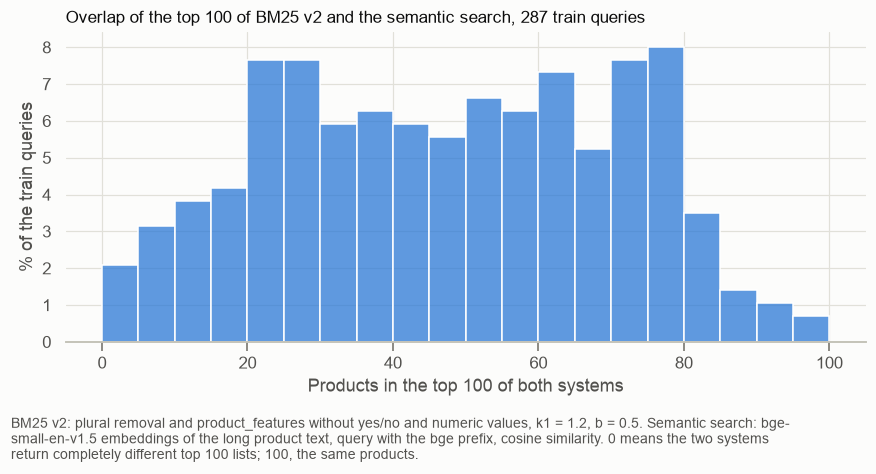

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(union_diagnostic["overlap@100"], bins=20, binrange=(0, 100), stat="percent", color=plots.SERIES_1, ax=ax)
ax.set_title(f"Overlap of the top 100 of BM25 v2 and the semantic search, {len(union_diagnostic)} train queries")
ax.set_xlabel("Products in the top 100 of both systems")
ax.set_ylabel("% of the train queries")
fig.tight_layout()
plots.add_caption(fig, (
    "BM25 v2: plural removal and product_features without yes/no and numeric values, k1 = 1.2, b = 0.5. Semantic search: "
    "bge-small-en-v1.5 embeddings of the long product text, query with the bge prefix, cosine similarity. "
    "0 means the two systems return completely different top 100 lists; 100, the same products."
))
plt.show()

**Resultados**
- **Em média, as duas listas têm 46,9 produtos em comum nos 100 primeiros** [44,2; 49,6]. O overlap varia muito entre queries, quase todo entre 20 e 80 produtos.
- **A union traz bem mais Exact que cada sistema sozinho:** o teto de Capped Recall@100 com a union dos 100 primeiros é 0,818, contra 0,731 da BM25 v2 e 0,708 da semantic search. São +0,087 [0,068; 0,106] sobre a BM25 v2, com o teto acima dela em 51,5% das 227 queries com Exact.
- **Com os 200 primeiros de cada lista, que é o que o RRF recebe, o teto sobe para 0,892** (+0,161 [0,133; 0,189] sobre a BM25 v2).

**O que isso implica (nossa interpretação)**
- Cada sistema traz Exact que o outro não traz, então há espaço para a hybrid search aumentar a cobertura dos 100 candidatos. O quanto ela aproveita depende de quais 100 produtos da union a fusão mantém, o que a Etapa 5.2 mede.

**Limitações**
- O teto supõe saber quais produtos são Exact, o que nenhuma fusão sabe; é um limite superior, não uma previsão.
- Medido no train set, que também escolheu a semantic search (Etapa 3.1) e os `k1` e `b` da BM25 v2.

### 5.2 · O peso w no train set

Para cada w da grade, fundimos as duas listas guardadas na Etapa 5.1 com `retrieval.rrf_fuse` e medimos os 100 primeiros (e os 200, para o Capped Recall@200) nas 287 queries do train set. Antes da grade, conferimos que essa fusão sobre as listas guardadas dá o mesmo resultado que o `retrieval.HybridRetriever`, que é o que roda no validation set.

**Regra de escolha:** maior Capped Recall@100 (só Exact); se a diferença para a melhor for menor que 0,005, desempata o NDCG@10. A BM25 v2 (que equivale a w = 1) e a semantic search (w = 0) aparecem na tabela só como referência; elas não fazem parte da grade.

O resultado da combinação escolhida no train set é otimista (é a melhor entre 5) e não entra na comparação entre sistemas.

In [18]:
HYBRID_WEIGHTS = (0.2, 0.35, 0.5, 0.65, 0.8)


def fused_train_search(weight: float, rrf_k: int = retrieval.RRF_K):
    """Search function of evaluate over the stored train lists: weighted RRF with constant rrf_k, weight w for BM25 v2 and 1 - w for the semantic search."""
    def search(query_text: str, k: int) -> list[int]:
        return retrieval.rrf_fuse(train_lists[query_text], k=rrf_k, weights=[weight, 1 - weight]).head(k)["product_id"].tolist()
    return search


hybrid_check = retrieval.HybridRetriever([v2_index, chosen_index], weights=[0.5, 0.5])
for query_text in train_queries["query"].head(20):
    assert hybrid_check.search(query_text, k=200)["product_id"].tolist() == fused_train_search(0.5)(query_text, 200)
print("fusion over the stored lists matches HybridRetriever on 20 train queries")

hybrid_grid = {f"w = {weight}": fused_train_search(weight) for weight in HYBRID_WEIGHTS}
hybrid_tuning, hybrid_tuning_per_query = evaluate.evaluate_grid(hybrid_grid, train_queries, labels_by_query)
hybrid_chosen = evaluate.select_tuned(hybrid_tuning)
hybrid_chosen_weight = HYBRID_WEIGHTS[list(hybrid_grid).index(hybrid_chosen["system"])]

hybrid_tuning_table = pd.concat([
    hybrid_tuning.set_index("system")[METRICS],
    pd.DataFrame({"BM25 v2 (w = 1, reference)": v2_train_per_query[METRICS].mean(),
                  "semantic search (w = 0, reference)": semantic_train_per_query[METRICS].mean()}).T,
]).rename_axis("weight of BM25 v2")
display(plots.table(hybrid_tuning_table, "Hybrid search tuning: mean of each metric on the 287 train queries, by the weight w of BM25 v2",
                    note="Weighted RRF: w / (60 + rank in BM25 v2) + (1 - w) / (60 + rank in the semantic search), top 200 of each list. "
                         "MRR@10 and Capped Recall: Exact only, 227 train queries with Exact.", precision=3))
print(f"chosen: {hybrid_chosen['system']} | train capped_recall@100 = {hybrid_chosen['capped_recall@100']:.3f}, "
      f"ndcg@10 = {hybrid_chosen['ndcg@10']:.3f}")

fusion over the stored lists matches HybridRetriever on 20 train queries


,ndcg@10,mrr@10,capped_recall@50,capped_recall@100,capped_recall@200,judged@10,condensed_ndcg@10
weight of BM25 v2,,,,,,,
w = 0.2,0.758,0.759,0.678,0.725,0.785,0.845,0.860
w = 0.35,0.763,0.757,0.687,0.738,0.805,0.856,0.860
w = 0.5,0.763,0.736,0.703,0.754,0.816,0.861,0.862
w = 0.65,0.760,0.738,0.692,0.744,0.818,0.856,0.859
w = 0.8,0.750,0.736,0.686,0.737,0.799,0.843,0.850
"BM25 v2 (w = 1, reference)",0.721,0.725,0.657,0.731,0.795,0.821,0.840
"semantic search (w = 0, reference)",0.739,0.723,0.653,0.708,0.773,0.828,0.853


chosen: w = 0.5 | train capped_recall@100 = 0.754, ndcg@10 = 0.763


In [19]:
hybrid_grid_differences = []
for name, per_query in [*hybrid_tuning_per_query.items(), ("BM25 v2 (w = 1, reference)", v2_train_per_query),
                        ("semantic search (w = 0, reference)", semantic_train_per_query)]:
    if name == hybrid_chosen["system"]:
        continue
    row = {"compared with the chosen weight": name}
    for metric in ["capped_recall@100", "ndcg@10"]:
        difference = evaluate.paired_bootstrap(per_query, hybrid_tuning_per_query[hybrid_chosen["system"]], metric)
        row[f"{metric} difference [95% CI]"] = evaluate.format_ci(difference["mean_difference"], difference["ci_low"], difference["ci_high"])
        row[f"{metric} excludes 0"] = difference["ci_low"] > 0 or difference["ci_high"] < 0
    hybrid_grid_differences.append(row)
plots.table(pd.DataFrame(hybrid_grid_differences).set_index("compared with the chosen weight"),
            f"Hybrid search tuning: each weight, and each system alone, minus the chosen weight ({hybrid_chosen['system']}), train set",
            note="Mean paired difference with 95% paired bootstrap interval. excludes 0: the interval does not contain 0.")

,capped_recall@100 difference [95% CI],capped_recall@100 excludes 0,ndcg@10 difference [95% CI],ndcg@10 excludes 0
compared with the chosen weight,,,,
w = 0.2,-0.029 [-0.047; -0.013],True,-0.005 [-0.014; 0.005],False
w = 0.35,-0.015 [-0.031; -0.004],True,-0.000 [-0.006; 0.006],False
w = 0.65,-0.010 [-0.019; -0.003],True,-0.003 [-0.009; 0.004],False
w = 0.8,-0.017 [-0.030; -0.005],True,-0.013 [-0.024; -0.001],True
"BM25 v2 (w = 1, reference)",-0.023 [-0.038; -0.008],True,-0.041 [-0.057; -0.025],True
"semantic search (w = 0, reference)",-0.046 [-0.066; -0.028],True,-0.024 [-0.039; -0.009],True


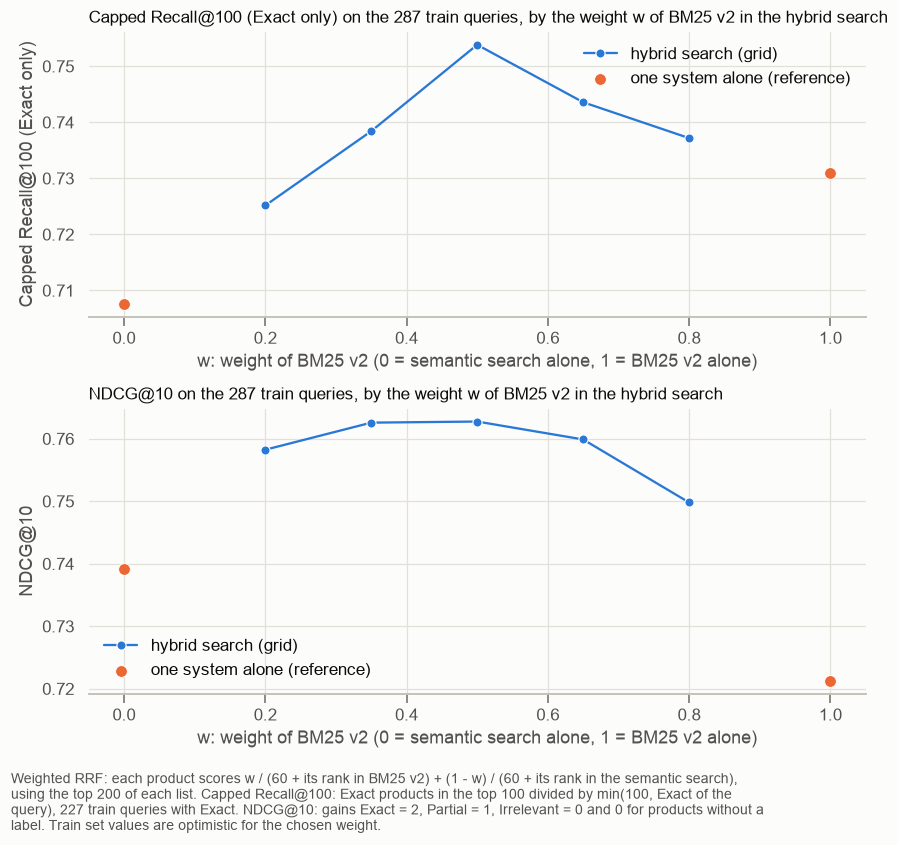

In [20]:
weight_curve = pd.concat([
    pd.DataFrame({"w": HYBRID_WEIGHTS, "kind": "hybrid search (grid)",
                  **{metric: hybrid_tuning.set_index("system").loc[list(hybrid_grid), metric].to_numpy() for metric in ["capped_recall@100", "ndcg@10"]}}),
    pd.DataFrame({"w": [0.0, 1.0], "kind": "one system alone (reference)",
                  **{metric: [semantic_train_per_query[metric].mean(), v2_train_per_query[metric].mean()] for metric in ["capped_recall@100", "ndcg@10"]}}),
])
fig, axes = plt.subplots(2, 1, figsize=(8, 7))
for ax, metric, label in [(axes[0], "capped_recall@100", "Capped Recall@100 (Exact only)"), (axes[1], "ndcg@10", "NDCG@10")]:
    sns.lineplot(data=weight_curve[weight_curve["kind"] == "hybrid search (grid)"], x="w", y=metric, marker="o", color=plots.SERIES_1,
                 label="hybrid search (grid)", ax=ax)
    sns.scatterplot(data=weight_curve[weight_curve["kind"] != "hybrid search (grid)"], x="w", y=metric, color=plots.SERIES_2, s=60,
                    label="one system alone (reference)", ax=ax)
    ax.set_title(f"{label} on the 287 train queries, by the weight w of BM25 v2 in the hybrid search")
    ax.set_xlabel("w: weight of BM25 v2 (0 = semantic search alone, 1 = BM25 v2 alone)")
    ax.set_ylabel(label)
fig.tight_layout()
plots.add_caption(fig, (
    "Weighted RRF: each product scores w / (60 + its rank in BM25 v2) + (1 - w) / (60 + its rank in the semantic search), "
    "using the top 200 of each list. Capped Recall@100: Exact products in the top 100 divided by min(100, Exact of the query), "
    "227 train queries with Exact. NDCG@10: gains Exact = 2, Partial = 1, Irrelevant = 0 and 0 for products without a label. "
    "Train set values are optimistic for the chosen weight."
))
plt.show()

**Resultados**
- **A fusão sobre as listas guardadas reproduz o `retrieval.HybridRetriever`** nas 20 queries conferidas.
- **Peso escolhido: w = 0,5, o RRF padrão,** com Capped Recall@100 de 0,754 e NDCG@10 de 0,763 no train set. Todos os outros pesos da grade têm Capped Recall@100 menor, com intervalos que excluem 0 (de −0,010 a −0,029). Em NDCG@10, só w = 0,8 fica abaixo com intervalo que exclui 0 (−0,013 [−0,024; −0,001]); de 0,2 a 0,65, os pesos não se distinguem.
- **No train set, a hybrid search com w = 0,5 supera os dois sistemas sozinhos nas duas métricas, com intervalos que excluem 0:** contra a BM25 v2, Capped Recall@100 +0,023 [0,008; 0,038] e NDCG@10 +0,041 [0,025; 0,057]; contra a semantic search, +0,046 [0,028; 0,066] e +0,024 [0,009; 0,039].
- **A hybrid search fica abaixo do teto da union:** 0,754, contra 0,818 da union dos 100 primeiros (Etapa 5.1).

**O que isso implica (nossa interpretação)**
- A pergunta "qual peso dar a cada lista" tem, no train set, a resposta do RRF padrão: mover o peso para qualquer lado da grade perde Exact nos 100 primeiros.
- Juntar as duas listas recupera cerca de um quarto da distância entre a BM25 v2 e o teto da union dos 100 primeiros (0,754 − 0,731 = 0,023, de 0,818 − 0,731 = 0,087).

**Limitações**
- O resultado do peso escolhido no train set é otimista (o melhor entre 5) e serve só para escolher. A comparação entre sistemas é a do validation set.
- A grade tem passos de 0,15; pesos entre 0,35 e 0,65 não foram testados.
- Os intervalos não corrigem para várias comparações.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Hybrid search com weighted RRF, w = 0,5, k = 60, 200 primeiros de cada lista | substituída pela grade conjunta de k e w da Etapa 5.3 | grade mais fina perto de 0,5; combinação linear dos scores normalizados (min-max ou z-score) |

### 5.3 · k e w juntos no train set

Na fórmula do weighted RRF, w / (k + posição na BM25 v2) + (1 − w) / (k + posição na semantic search), a constante k decide quanto vale estar no topo de uma lista contra estar nas duas:
- **k pequeno (10):** o 1º lugar vale 1/11 e o 50º vale 1/60, cerca de 5 vezes menos. Um produto no topo de uma só lista entra fácil nos 100 primeiros.
- **k grande (100):** o 1º lugar vale 1/101 e o 50º vale 1/150, só 1,5 vez menos. Pesa mais aparecer nas duas listas, mesmo em posições medianas.

A Etapa 5.2 usou k = 60, o valor do RRF original. Como a união dos 200 primeiros de cada lista tem até 400 produtos e k decide quais 100 ficam, e como o melhor w pode depender de k, a grade registrada no `docs/EVALUATION.md` (que substitui a da Etapa 5.2) testa k e w juntos: k em {10, 30, 60, 100} × w em {0,2; 0,35; 0,5; 0,65; 0,8}, 20 combinações, que incluem a da Etapa 5.2 (k = 60, w = 0,5). Mesma regra de escolha e mesmas listas guardadas na Etapa 5.1.

O resultado da combinação escolhida no train set é otimista (é a melhor entre 20) e não entra na comparação entre sistemas.

In [21]:
RRF_K_GRID = (10, 30, 60, 100)


def joint_name(rrf_k: int, weight: float) -> str:
    return f"k = {rrf_k}, w = {weight}"


joint_grid_keys = {joint_name(rrf_k, weight): (rrf_k, weight) for rrf_k in RRF_K_GRID for weight in HYBRID_WEIGHTS}
joint_tuning, joint_tuning_per_query = evaluate.evaluate_grid(
    {name: fused_train_search(weight, rrf_k) for name, (rrf_k, weight) in joint_grid_keys.items()}, train_queries, labels_by_query)
joint_tuning["k"] = joint_tuning["system"].map(lambda name: joint_grid_keys[name][0])
joint_tuning["w"] = joint_tuning["system"].map(lambda name: joint_grid_keys[name][1])


def k_w_labels(grid: pd.DataFrame) -> pd.DataFrame:
    """Label the rows and columns of a k x w grid as 'k = ...' and 'w = ...'."""
    return grid.rename(index=lambda rrf_k: f"k = {rrf_k}", columns=lambda weight: f"w = {weight}").rename_axis(index=None, columns=None)


display(plots.table(joint_tuning.pivot(index="k", columns="w", values="capped_recall@100").pipe(k_w_labels),
                    "Hybrid search tuning: Capped Recall@100 (Exact only) on the train set, by the RRF constant k and the weight w of BM25 v2",
                    note="Weighted RRF: w / (k + rank in BM25 v2) + (1 - w) / (k + rank in the semantic search), top 200 of each list. "
                         "227 train queries with Exact.", precision=3))
display(plots.table(joint_tuning.pivot(index="k", columns="w", values="ndcg@10").pipe(k_w_labels),
                    "Hybrid search tuning: NDCG@10 on the train set, by the RRF constant k and the weight w of BM25 v2",
                    note="287 train queries.", precision=3))
joint_chosen = evaluate.select_tuned(joint_tuning)
joint_chosen_k, joint_chosen_weight = joint_grid_keys[joint_chosen["system"]]
print(f"chosen: {joint_chosen['system']} | train capped_recall@100 = {joint_chosen['capped_recall@100']:.3f}, "
      f"ndcg@10 = {joint_chosen['ndcg@10']:.3f}")
print("combinations within 0.005 of the best Capped Recall@100:",
      joint_tuning.loc[joint_tuning["capped_recall@100"] >= joint_tuning["capped_recall@100"].max() - evaluate.TUNING_TOLERANCE, "system"].tolist())

,w = 0.2,w = 0.35,w = 0.5,w = 0.65,w = 0.8
k = 10,0.735,0.749,0.751,0.749,0.743
k = 30,0.725,0.750,0.752,0.748,0.736
k = 60,0.725,0.738,0.754,0.744,0.737
k = 100,0.725,0.731,0.753,0.740,0.738


,w = 0.2,w = 0.35,w = 0.5,w = 0.65,w = 0.8
k = 10,0.748,0.756,0.756,0.747,0.731
k = 30,0.755,0.760,0.762,0.753,0.742
k = 60,0.758,0.763,0.763,0.760,0.750
k = 100,0.759,0.764,0.762,0.761,0.757


chosen: k = 60, w = 0.5 | train capped_recall@100 = 0.754, ndcg@10 = 0.763
combinations within 0.005 of the best Capped Recall@100: ['k = 10, w = 0.5', 'k = 10, w = 0.65', 'k = 30, w = 0.35', 'k = 30, w = 0.5', 'k = 60, w = 0.5', 'k = 100, w = 0.5']


In [22]:
joint_differences = []
for name, per_query in joint_tuning_per_query.items():
    if name == joint_chosen["system"]:
        continue
    row = {"k": f"k = {joint_grid_keys[name][0]}", "w": f"w = {joint_grid_keys[name][1]}"}
    for metric in ["capped_recall@100", "ndcg@10"]:
        difference = evaluate.paired_bootstrap(per_query, joint_tuning_per_query[joint_chosen["system"]], metric)
        row[f"{metric} difference [95% CI]"] = evaluate.format_ci(difference["mean_difference"], difference["ci_low"], difference["ci_high"])
        row[f"{metric} excludes 0"] = difference["ci_low"] > 0 or difference["ci_high"] < 0
    joint_differences.append(row)
joint_differences = pd.DataFrame(joint_differences).set_index(["k", "w"])
display(plots.table(joint_differences, f"Hybrid search tuning: each (k, w) minus the chosen one ({joint_chosen['system']}), train set",
                    note="Mean paired difference with 95% paired bootstrap interval. excludes 0: the interval does not contain 0."))
plots.table(joint_differences[["capped_recall@100 excludes 0", "ndcg@10 excludes 0"]].sum().rename("combinations").to_frame(),
            f"Number of the {len(joint_differences)} other combinations whose difference interval excludes 0")

,combinations
capped_recall@100 excludes 0,13
ndcg@10 excludes 0,5


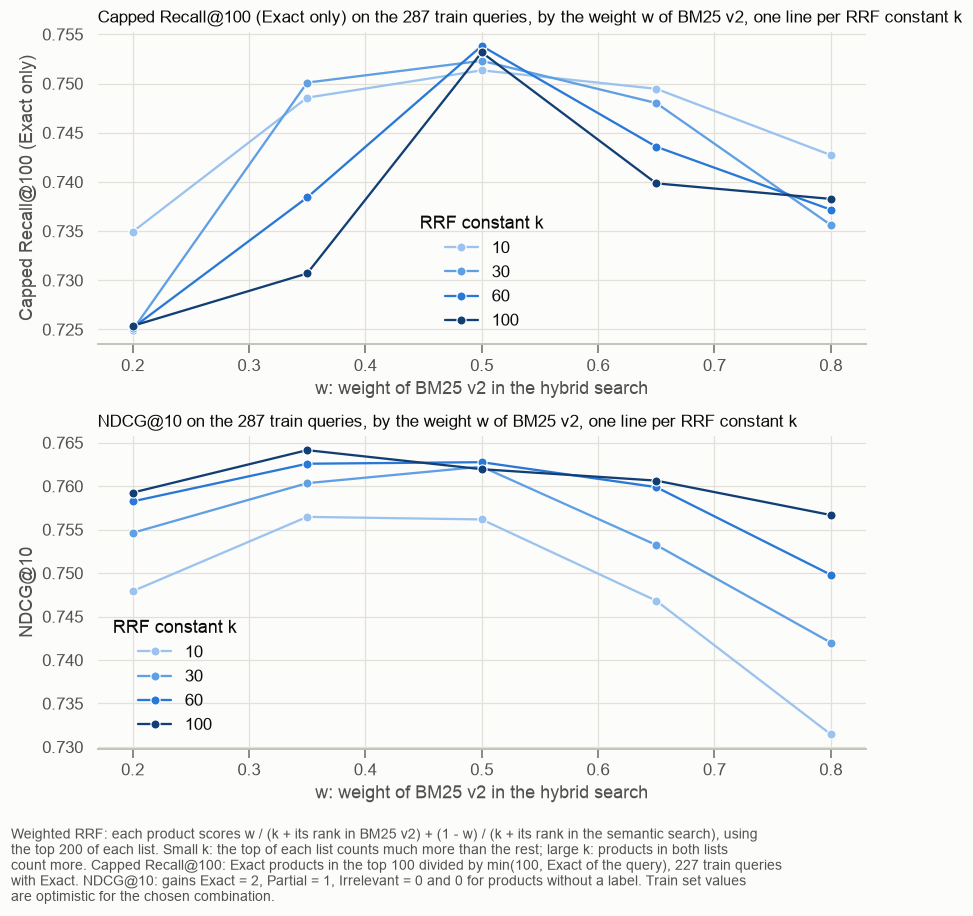

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(8, 7.5))
k_palette = dict(zip(RRF_K_GRID, ["#9cc3ee", "#5f9fe3", plots.SERIES_1, "#123f73"]))
for ax, metric, label in [(axes[0], "capped_recall@100", "Capped Recall@100 (Exact only)"), (axes[1], "ndcg@10", "NDCG@10")]:
    sns.lineplot(data=joint_tuning, x="w", y=metric, hue="k", palette=k_palette, marker="o", ax=ax)
    ax.set_title(f"{label} on the 287 train queries, by the weight w of BM25 v2, one line per RRF constant k")
    ax.set_xlabel("w: weight of BM25 v2 in the hybrid search")
    ax.set_ylabel(label)
    ax.legend(title="RRF constant k")
fig.tight_layout()
plots.add_caption(fig, (
    "Weighted RRF: each product scores w / (k + its rank in BM25 v2) + (1 - w) / (k + its rank in the semantic search), "
    "using the top 200 of each list. Small k: the top of each list counts much more than the rest; large k: products in both "
    "lists count more. Capped Recall@100: Exact products in the top 100 divided by min(100, Exact of the query), 227 train queries "
    "with Exact. NDCG@10: gains Exact = 2, Partial = 1, Irrelevant = 0 and 0 for products without a label. Train set values are "
    "optimistic for the chosen combination."
))
plt.show()

**Resultados**
- **A grade conjunta mantém a escolha da Etapa 5.2: k = 60, w = 0,5,** com Capped Recall@100 de 0,754 e NDCG@10 de 0,763 no train set. Seis combinações ficam a menos de 0,005 do máximo de Capped Recall@100 (k = 10 com w = 0,5 e 0,65; k = 30 com w = 0,35 e 0,5; k = 60 e k = 100 com w = 0,5). Entre elas, k = 60, w = 0,5 tem o maior NDCG@10 e vence pelo desempate.
- **Nenhuma outra combinação é melhor que a escolhida com intervalo que exclui 0,** em nenhuma das duas métricas. 13 das 19 têm Capped Recall@100 menor com intervalo que exclui 0, e 5 têm NDCG@10 menor.
- **Com w = 0,5, k quase não importa:** Capped Recall@100 de 0,751 a 0,754 nos quatro valores de k, e as diferenças para a escolhida (−0,001 a −0,002) têm intervalos que incluem 0.
- **Longe de w = 0,5, k muda o resultado:** com k = 10, pesos desequilibrados perdem menos Capped Recall@100 (0,735 com w = 0,2, contra 0,725 nos outros k), mas k = 10 tem o menor NDCG@10 em todos os pesos (de 0,731 a 0,756).

**O que isso implica (nossa interpretação)**
- Nos nossos dados, o k = 60 do RRF original e o peso igual já estão no melhor ponto da grade. Testar k respondeu à pergunta sem mudar a configuração que vai para o validation set.

**Limitações**
- O resultado da combinação escolhida no train set é otimista (a melhor entre 20) e serve só para escolher.
- A grade é grossa (4 valores de k, passos de 0,15 em w), e os intervalos não corrigem para 19 comparações.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Hybrid search com weighted RRF, k = 60, w = 0,5, 200 primeiros de cada lista, pela regra registrada no `docs/EVALUATION.md` | decidida | grade mais fina perto de k = 60 e w = 0,5; outro número de produtos por lista (`RRF_DEPTH`); combinação linear dos scores normalizados (min-max ou z-score) |

## Etapa 6 · Hybrid search no validation set e o retrieval que fornece os candidatos do reranker

Rodamos uma única vez, nas 97 queries do validation set, a hybrid search escolhida no train set na Etapa 5.3: weighted RRF com k = 60 e w = 0,5 (o RRF padrão), sobre os 200 primeiros da BM25 v2 e da semantic search (long text com bge prefix). Usamos o `retrieval.HybridRetriever` pelo mesmo procedimento das Etapas 4.1 e 4.2 (`evaluate.evaluate_system`, 200 primeiros, 20 buscas de aquecimento), e comparamos com os dois sistemas sozinhos pelo paired bootstrap. As medidas da BM25 v2 e da semantic search são as da Etapa 4.1, nas mesmas queries.

Duas regras do `docs/EVALUATION.md`, registradas antes de rodar, usam esta comparação:
- **retrieval que fornece os candidatos do reranker:** entre BM25 v2, semantic search e hybrid search, o de maior Capped Recall@100 no validation set; se o intervalo de 95% do paired bootstrap da diferença para um sistema mais simples incluir 0, fica o mais simples (BM25 v2 < semantic search < hybrid search). Aplicada na Etapa 6.2.
- **seleção final entre sistemas:** pelo NDCG@10, depois do reranker. Aqui só registramos os números.

### 6.1 · Métricas e latência

In [24]:
hybrid_index = retrieval.HybridRetriever([v2_index, chosen_index], k=joint_chosen_k, weights=[joint_chosen_weight, 1 - joint_chosen_weight])
print(f"hybrid search: k = {hybrid_index.k}, weights = {hybrid_index.weights}, top {hybrid_index.depth} of each list")
hybrid_validation_per_query = evaluate.evaluate_system(search_function(hybrid_index), validation_queries, labels_by_query)

validation_per_query = {"BM25 v2": v2_validation_per_query, "semantic": semantic_validation_per_query, "hybrid": hybrid_validation_per_query}
validation_summary = pd.DataFrame({
    system: evaluate.summary_table(per_query).loc[METRICS].apply(
        lambda row: evaluate.format_ci(row["mean"], row["ci_low"], row["ci_high"]), axis=1)
    for system, per_query in validation_per_query.items()
}).rename_axis("metric")
display(plots.table(validation_summary, "BM25 v2, semantic search and hybrid search on the 97 validation queries",
                    note="Mean with 95% bootstrap interval. MRR@10 and Capped Recall: Exact only, 77 validation queries with Exact. "
                         "Hybrid search: weighted RRF, k = 60, w = 0.5, top 200 of each list."))

hybrid_comparisons = {
    other: evaluate.compare_systems(hybrid_validation_per_query, validation_per_query[other], METRICS, name_a="hybrid", name_b="other")
    for other in ["BM25 v2", "semantic"]
}
display(plots.table(pd.DataFrame({f"hybrid - {other}": comparison["difference_ci"] for other, comparison in hybrid_comparisons.items()})
                    .join(pd.DataFrame({f"excludes 0 vs {other}": comparison["interval_excludes_0"] for other, comparison in hybrid_comparisons.items()}))
                    .rename_axis("metric"),
                    "Hybrid search minus each system alone on the validation set",
                    note="Mean paired difference with 95% paired bootstrap interval. excludes 0: the interval does not contain 0."))
plots.table(pd.DataFrame({
    system: per_query["latency_ms"].quantile([0.5, 0.95]).set_axis(["latency_ms_p50", "latency_ms_p95"])
    for system, per_query in validation_per_query.items()
}), "Latency of one search (k = 200), validation set", precision=2,
    note=f"One process on {platform.platform()} ({platform.processor()}), CPU only, after {evaluate.WARMUP_QUERIES} warm-up searches. "
         "BM25 v2 and semantic search: Etapa 4.1 run.")

hybrid search: k = 60, weights = [0.5, 0.5], top 200 of each list


,BM25 v2,semantic,hybrid
metric,,,
ndcg@10,0.653 [0.589; 0.718],0.725 [0.668; 0.785],0.747 [0.690; 0.805]
mrr@10,0.661 [0.564; 0.752],0.661 [0.565; 0.752],0.681 [0.585; 0.766]
capped_recall@50,0.651 [0.572; 0.730],0.634 [0.553; 0.710],0.677 [0.599; 0.751]
capped_recall@100,0.705 [0.628; 0.778],0.678 [0.601; 0.751],0.714 [0.640; 0.784]
capped_recall@200,0.786 [0.715; 0.851],0.761 [0.690; 0.821],0.800 [0.736; 0.858]
judged@10,0.782 [0.719; 0.839],0.824 [0.770; 0.874],0.854 [0.805; 0.900]
condensed_ndcg@10,0.799 [0.749; 0.851],0.836 [0.792; 0.878],0.834 [0.787; 0.879]


,hybrid - BM25 v2,hybrid - semantic,excludes 0 vs BM25 v2,excludes 0 vs semantic
metric,,,,
ndcg@10,0.094 [0.063; 0.128],0.022 [-0.003; 0.048],True,False
mrr@10,0.020 [-0.032; 0.075],0.020 [-0.031; 0.073],False,False
capped_recall@50,0.025 [-0.009; 0.064],0.043 [0.023; 0.066],False,True
capped_recall@100,0.008 [-0.008; 0.028],0.035 [-0.003; 0.068],False,False
capped_recall@200,0.014 [-0.018; 0.051],0.039 [0.019; 0.061],False,True
judged@10,0.080 [0.050; 0.116],0.030 [0.002; 0.059],True,True
condensed_ndcg@10,0.035 [0.013; 0.058],-0.002 [-0.020; 0.014],True,False


,BM25 v2,semantic,hybrid
latency_ms_p50,0.94,7.84,13.41
latency_ms_p95,3.40,8.58,18.36


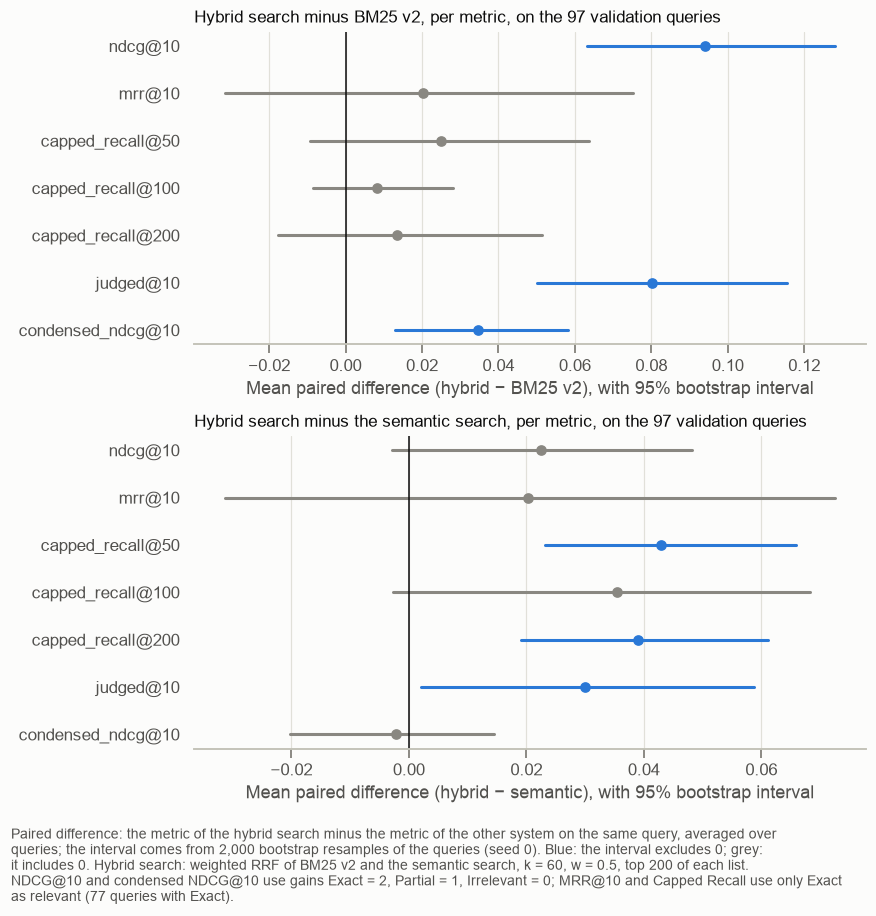

In [25]:
fig, axes = plt.subplots(2, 1, figsize=(8, 7.5))
for ax, other in zip(axes, ["BM25 v2", "semantic"]):
    comparison = hybrid_comparisons[other]
    plots.difference_plot(ax, list(comparison.index), comparison["difference"], comparison["difference_ci_low"], comparison["difference_ci_high"])
    ax.set_title(f"Hybrid search minus {'the semantic search' if other == 'semantic' else other}, per metric, on the 97 validation queries")
    ax.set_xlabel(f"Mean paired difference (hybrid − {other}), with 95% bootstrap interval")
fig.tight_layout()
plots.add_caption(fig, (
    "Paired difference: the metric of the hybrid search minus the metric of the other system on the same query, averaged over "
    "queries; the interval comes from 2,000 bootstrap resamples of the queries (seed 0). Blue: the interval excludes 0; grey: it "
    "includes 0. Hybrid search: weighted RRF of BM25 v2 and the semantic search, k = 60, w = 0.5, top 200 of each list. "
    "NDCG@10 and condensed NDCG@10 use gains Exact = 2, Partial = 1, Irrelevant = 0; MRR@10 and Capped Recall use only Exact "
    "as relevant (77 queries with Exact)."
))
plt.show()

**Resultados**
- **A hybrid search tem o maior valor dos três sistemas em todas as métricas, menos o condensed NDCG@10:** NDCG@10 de 0,747 (BM25 v2 0,653; semantic search 0,725), MRR@10 de 0,681, Capped Recall@100 de 0,714 (0,705; 0,678) e judged@10 de 0,854 (0,782; 0,824). No condensed NDCG@10, fica em 0,834, contra 0,836 da semantic search.
- **Contra a BM25 v2, a hybrid search ganha na ordem do topo, mas não se distingue na cobertura:** NDCG@10 +0,094 [0,063; 0,128], condensed NDCG@10 +0,035 [0,013; 0,058] e judged@10 +0,080 [0,050; 0,116], com intervalos que excluem 0; Capped Recall@100 +0,008 [−0,008; 0,028] e MRR@10 +0,020 [−0,032; 0,075], com intervalos que incluem 0.
- **Contra a semantic search, a hybrid search ganha na cobertura em 50 e 200, mas não se distingue no topo:** Capped Recall@50 +0,043 [0,023; 0,066] e Capped Recall@200 +0,039 [0,019; 0,061], com intervalos que excluem 0; NDCG@10 +0,022 [−0,003; 0,048] e Capped Recall@100 +0,035 [−0,003; 0,068], com intervalos que incluem 0.
- **Na execução salva, a hybrid search leva 13,41 ms no p50 e 18,36 ms no p95,** acima da soma das duas buscas no p50 (0,94 ms da BM25 v2 e 7,84 ms da semantic search). Além das duas buscas, ela faz a fusão das listas em Python; não medimos essa parte separadamente.

**O que isso implica (nossa interpretação)**
- No train set, a hybrid search tinha Capped Recall@100 maior que o da BM25 v2 com intervalo que excluía 0 (+0,023, Etapa 5.3). No validation set, a diferença é menor (+0,008) e não se distingue de 0. Com 77 queries, uma diferença desse tamanho não seria detectada mesmo que existisse.
- A regra "produto sem `label` = gain 0" não inverte a comparação com a BM25 v2: a hybrid search continua à frente no condensed NDCG@10.

**Limitações**
- Só 77 queries do validation set têm Exact, então os intervalos do Capped Recall e do MRR@10 são largos.
- A latência é de uma execução, numa máquina, só com CPU. A da hybrid search variou bastante entre execuções durante o desenvolvimento (p50 de 9,4 ms numa execução anterior), então só a ordem de grandeza (cerca de 10 ms) é estável.

### 6.2 · O retrieval que fornece os candidatos do reranker

Aplicamos a regra registrada no `docs/EVALUATION.md`: o sistema de maior Capped Recall@100 no validation set; se o intervalo da diferença para um sistema mais simples incluir 0, fica o mais simples, na ordem BM25 v2 < semantic search < hybrid search.

In [26]:
SIMPLICITY_ORDER = ["BM25 v2", "semantic", "hybrid"]
recall_means = {system: validation_per_query[system]["capped_recall@100"].mean() for system in SIMPLICITY_ORDER}
best_recall_system = max(recall_means, key=recall_means.get)

candidate_rule = []
for simpler in SIMPLICITY_ORDER[:SIMPLICITY_ORDER.index(best_recall_system)]:
    difference = evaluate.paired_bootstrap(validation_per_query[best_recall_system], validation_per_query[simpler], "capped_recall@100")
    candidate_rule.append({
        "simpler system": simpler,
        f"{best_recall_system} - simpler [95% CI]": evaluate.format_ci(difference["mean_difference"], difference["ci_low"], difference["ci_high"]),
        "interval includes 0": difference["ci_low"] <= 0 <= difference["ci_high"],
    })
candidate_rule = pd.DataFrame(candidate_rule)
candidate_retrieval = next((row["simpler system"] for _, row in candidate_rule.iterrows() if row["interval includes 0"]), best_recall_system)

display(plots.table(pd.Series(recall_means, name="capped_recall@100").to_frame().rename_axis("system"),
                    "Capped Recall@100 (Exact only) of each retrieval on the 77 validation queries with Exact", precision=3))
if len(candidate_rule):
    display(plots.table(candidate_rule.set_index("simpler system"),
                        f"Capped Recall@100 of the best retrieval ({best_recall_system}) minus each simpler one, validation set",
                        note="Mean paired difference with 95% paired bootstrap interval. If an interval includes 0, the simplest such system is kept."))
print(f"highest Capped Recall@100: {best_recall_system} | retrieval that provides the reranker candidates: {candidate_retrieval}")

,capped_recall@100
system,
BM25 v2,0.705
semantic,0.678
hybrid,0.714


,hybrid - simpler [95% CI],interval includes 0
simpler system,,
BM25 v2,0.008 [-0.008; 0.028],True
semantic,0.035 [-0.003; 0.068],True


highest Capped Recall@100: hybrid | retrieval that provides the reranker candidates: BM25 v2


**Resultados**
- **A hybrid search tem o maior Capped Recall@100 (0,714),** mas o intervalo da diferença inclui 0 tanto para a BM25 v2 (+0,008 [−0,008; 0,028]) quanto para a semantic search (+0,035 [−0,003; 0,068]).
- **Pela regra registrada antes de rodar, os candidatos do reranker viriam da BM25 v2,** o mais simples dos sistemas cuja diferença inclui 0.

**Regra substituída depois desta etapa.** No validation set, a hybrid search e a BM25 v2 empatam na cobertura (melhor em 19 das 77 queries com Exact, pior em 16, igual em 42), mas a hybrid search ordena melhor (NDCG@10 +0,094, Etapa 6.1). A regra decidia só pela cobertura e tratava "o intervalo inclui 0" como igualdade, com 77 queries. O `docs/EVALUATION.md` registra a nova regra, decidida depois desta etapa e antes de qualquer número do reranker: **o reranker é treinado sobre os candidatos dos dois retrievals (BM25 v2 e hybrid search), e a seleção final entre os sistemas, pelo NDCG@10, decide.**

**O que isso implica (nossa interpretação)**
- A informação da semantic search entra também como feature: a cosine similarity entre a query e cada candidato.

**Limitações**
- A mudança de regra foi feita depois de ver os resultados dos três retrievals no validation set. Ela não escolhe um sistema (a escolha passa para a métrica principal, já registrada), mas acrescenta uma comparação no validation set.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Candidatos do reranker: os 100 primeiros da BM25 v2 (regra pelo Capped Recall@100) | substituída | – |
| Reranker treinado sobre os 100 primeiros da BM25 v2 e sobre os 100 primeiros da hybrid search; a seleção final pelo NDCG@10 decide | decidida | só a BM25 v2, com a hybrid search como ablation; só a hybrid search |

## Etapa 7 · Que tipo de query cada sistema acerta

Nas Etapas 4 a 6, a BM25 v2 tem Capped Recall@100 igual ou maior que o da semantic search, e a semantic search tem NDCG@10 maior. Aqui perguntamos se isso depende do tipo de query: as queries justificam a BM25 v2, e em quais casos?

Usamos as 384 queries do train e do validation set juntas, para ter grupos maiores. Os sistemas não aprendem com os `label`, e esta etapa não escolhe nada; é descritiva e serve de base para a error analysis. O test set não é usado.

### 7.1 · Os tipos de query

Cada query é descrita pelos seus tokens (com a remoção de plural da BM25 v2) contra o catalog, com `profiling.query_token_descriptors`:
- **rare token:** o token mais raro da query (entre os que existem no catalog) aparece em 1 a 30 produtos. É típico de nome de produto ou de marca;
- **token fora do catalog:** algum token da query não aparece em nenhum produto (typos, marcas que o catalog não tem);
- **número:** algum token só de dígitos, em geral uma medida (`46 inch closet door`);
- **tamanho:** 1 a 2, 3, ou 4 ou mais tokens.

Os grupos se sobrepõem: uma query pode ter número e rare token ao mesmo tempo.

In [27]:
RARE_TOKEN_MAX_PRODUCTS = 30
analysis_queries = train_validation_queries.merge(query_split, left_on="query_id", right_index=True).set_index("query_id")
v2_product_tokens = retrieval.single_field_tokens(products, **retrieval.V2_TEXT)
query_descriptors = profiling.query_token_descriptors(analysis_queries["query"], v2_product_tokens, stem=True)

display(plots.table(query_descriptors["rarest_token_products"].quantile([0.1, 0.25, 0.5, 0.75, 0.9])
                    .rename(lambda q: f"{q:.0%} percentile").rename("products").to_frame().T,
                    "Products of the catalog that contain the rarest token of the query, 384 train and validation queries",
                    note="Rarest token: the query token, among those the catalog has, that is in the fewest products. "
                         + plots.TOKEN_DEFINITION, precision=0))

QUERY_GROUPS = {
    "all queries": pd.Series(True, index=query_descriptors.index),
    f"rare token (in 1 to {RARE_TOKEN_MAX_PRODUCTS} products)": query_descriptors["rarest_token_products"].between(1, RARE_TOKEN_MAX_PRODUCTS),
    "no rare token": ~query_descriptors["rarest_token_products"].between(1, RARE_TOKEN_MAX_PRODUCTS),
    "token missing from the catalog": query_descriptors["has_unknown_token"],
    "has a number": query_descriptors["has_number"],
    "1 to 2 tokens": query_descriptors["n_tokens"] <= 2,
    "3 tokens": query_descriptors["n_tokens"] == 3,
    "4 or more tokens": query_descriptors["n_tokens"] >= 4,
}
group_sizes = pd.DataFrame({
    group_name: analysis_queries.loc[in_group, "split"].value_counts().reindex(["train", "validation"]).fillna(0).astype(int)
    for group_name, in_group in QUERY_GROUPS.items()
}).T.rename_axis("query group")
group_sizes["share of the 384 queries (%)"] = group_sizes.sum(axis=1) / len(analysis_queries) * 100
plots.table(group_sizes, "Train and validation queries in each query group",
            note="Groups overlap. Rare token: the rarest query token is in 1 to 30 catalog products. " + plots.TOKEN_DEFINITION)

,10% percentile,25% percentile,50% percentile,75% percentile,90% percentile
products,4,35,238,740,"1,813"


split,train,validation,share of the 384 queries (%)
query group,,,
all queries,287,97,100.0
rare token (in 1 to 30 products),67,23,23.4
no rare token,220,74,76.6
token missing from the catalog,19,6,6.5
has a number,21,8,7.6
1 to 2 tokens,75,32,27.9
3 tokens,106,24,33.9
4 or more tokens,106,41,38.3


**Resultados**
- **O token mais raro da query aparece em até 35 produtos em um quarto das queries** (percentil 25), e em 238 produtos na mediana.
- **90 das 384 queries (23,4%) têm um rare token** (em 1 a 30 produtos), 25 (6,5%) têm um token fora do catalog e 29 (7,6%) têm um número. Os grupos têm proporções parecidas no train e no validation set (rare token em 67 de 287 e em 23 de 97).

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Rare token = em 1 a 30 produtos, perto do percentil 25 | proposta (só para esta análise) | outros cortes; classificar as queries à mão (nome de produto, marca, atributo, categoria); agrupar por `query_class` |

### 7.2 · As métricas de cada sistema em cada grupo

Rodamos os três sistemas (sem medir tempo) nas 384 queries e calculamos o NDCG@10 e o Capped Recall@100 em cada grupo, com a diferença pareada semantic search − BM25 v2 e hybrid search − BM25 v2. Os valores por query são os mesmos das Etapas 4.1, 5.3 e 6.1, porque os sistemas são determinísticos.

In [28]:
analysis_systems = {"BM25 v2": v2_index, "semantic": chosen_index, "hybrid": hybrid_index}
analysis_runs = {
    system: {query_id: index.search(query_text, k=evaluate.RETRIEVAL_K)["product_id"].tolist()
             for query_id, query_text in analysis_queries["query"].items()}
    for system, index in analysis_systems.items()
}
analysis_per_query = {system: metrics.evaluate_run(run, labels_by_query) for system, run in analysis_runs.items()}

group_metrics, group_differences = [], []
for group_name, in_group in QUERY_GROUPS.items():
    query_ids = in_group.index[in_group]
    means = {"query group": group_name, "queries": len(query_ids)}
    differences = {"query group": group_name}
    for metric in ["ndcg@10", "capped_recall@100"]:
        for system in analysis_systems:
            means[f"{metric} {system}"] = analysis_per_query[system].loc[query_ids, metric].mean()
        for system in ["semantic", "hybrid"]:
            difference = evaluate.paired_bootstrap(analysis_per_query[system].loc[query_ids], analysis_per_query["BM25 v2"].loc[query_ids], metric)
            differences[f"{metric}: {system} - BM25 v2"] = difference["mean_difference"]
            differences[f"{metric}: {system} - BM25 v2 low"] = difference["ci_low"]
            differences[f"{metric}: {system} - BM25 v2 high"] = difference["ci_high"]
            differences[f"{metric}: {system} - BM25 v2 [95% CI]"] = evaluate.format_ci(difference["mean_difference"], difference["ci_low"], difference["ci_high"])
    group_metrics.append(means)
    group_differences.append(differences)
group_metrics = pd.DataFrame(group_metrics).set_index("query group")
group_differences = pd.DataFrame(group_differences).set_index("query group")

display(plots.table(group_metrics, "NDCG@10 and Capped Recall@100 of each system in each query group, 384 train and validation queries",
                    note="Capped Recall@100: Exact only, over the queries of the group that have Exact. Groups overlap. "
                         "Hybrid search: weighted RRF, k = 60, w = 0.5.", precision=3))
plots.table(group_differences[[column for column in group_differences.columns if column.endswith("[95% CI]")]],
            "Semantic search and hybrid search minus BM25 v2 in each query group, 384 train and validation queries",
            note="Mean paired difference with 95% paired bootstrap interval. The intervals are not corrected for the number of groups.")

,queries,ndcg@10 BM25 v2,ndcg@10 semantic,ndcg@10 hybrid,capped_recall@100 BM25 v2,capped_recall@100 semantic,capped_recall@100 hybrid
query group,,,,,,,
all queries,384,0.704,0.735,0.759,0.724,0.700,0.744
rare token (in 1 to 30 products),90,0.742,0.777,0.799,0.865,0.848,0.876
no rare token,294,0.692,0.723,0.747,0.688,0.662,0.710
token missing from the catalog,25,0.609,0.562,0.661,0.582,0.513,0.562
has a number,29,0.647,0.667,0.729,0.844,0.703,0.826
1 to 2 tokens,107,0.784,0.794,0.812,0.786,0.776,0.817
3 tokens,130,0.649,0.699,0.714,0.637,0.619,0.668
4 or more tokens,147,0.695,0.724,0.760,0.754,0.713,0.754


,ndcg@10: semantic - BM25 v2 [95% CI],ndcg@10: hybrid - BM25 v2 [95% CI],capped_recall@100: semantic - BM25 v2 [95% CI],capped_recall@100: hybrid - BM25 v2 [95% CI]
query group,,,,
all queries,0.031 [0.011; 0.052],0.055 [0.039; 0.070],-0.024 [-0.046; -0.001],0.019 [0.008; 0.031]
rare token (in 1 to 30 products),0.035 [-0.012; 0.080],0.057 [0.026; 0.086],-0.018 [-0.062; 0.021],0.011 [-0.005; 0.037]
no rare token,0.030 [0.007; 0.053],0.054 [0.037; 0.071],-0.026 [-0.053; 0.001],0.021 [0.008; 0.036]
token missing from the catalog,-0.047 [-0.143; 0.056],0.051 [-0.005; 0.114],-0.068 [-0.139; 0.001],-0.019 [-0.057; 0.022]
has a number,0.019 [-0.043; 0.083],0.081 [0.034; 0.134],-0.140 [-0.220; -0.066],-0.018 [-0.047; 0.003]
1 to 2 tokens,0.011 [-0.026; 0.049],0.028 [0.003; 0.055],-0.010 [-0.041; 0.022],0.031 [0.011; 0.055]
3 tokens,0.051 [0.012; 0.089],0.065 [0.038; 0.093],-0.018 [-0.065; 0.029],0.031 [0.009; 0.054]
4 or more tokens,0.030 [-0.000; 0.062],0.065 [0.042; 0.091],-0.041 [-0.074; -0.007],-0.001 [-0.017; 0.015]


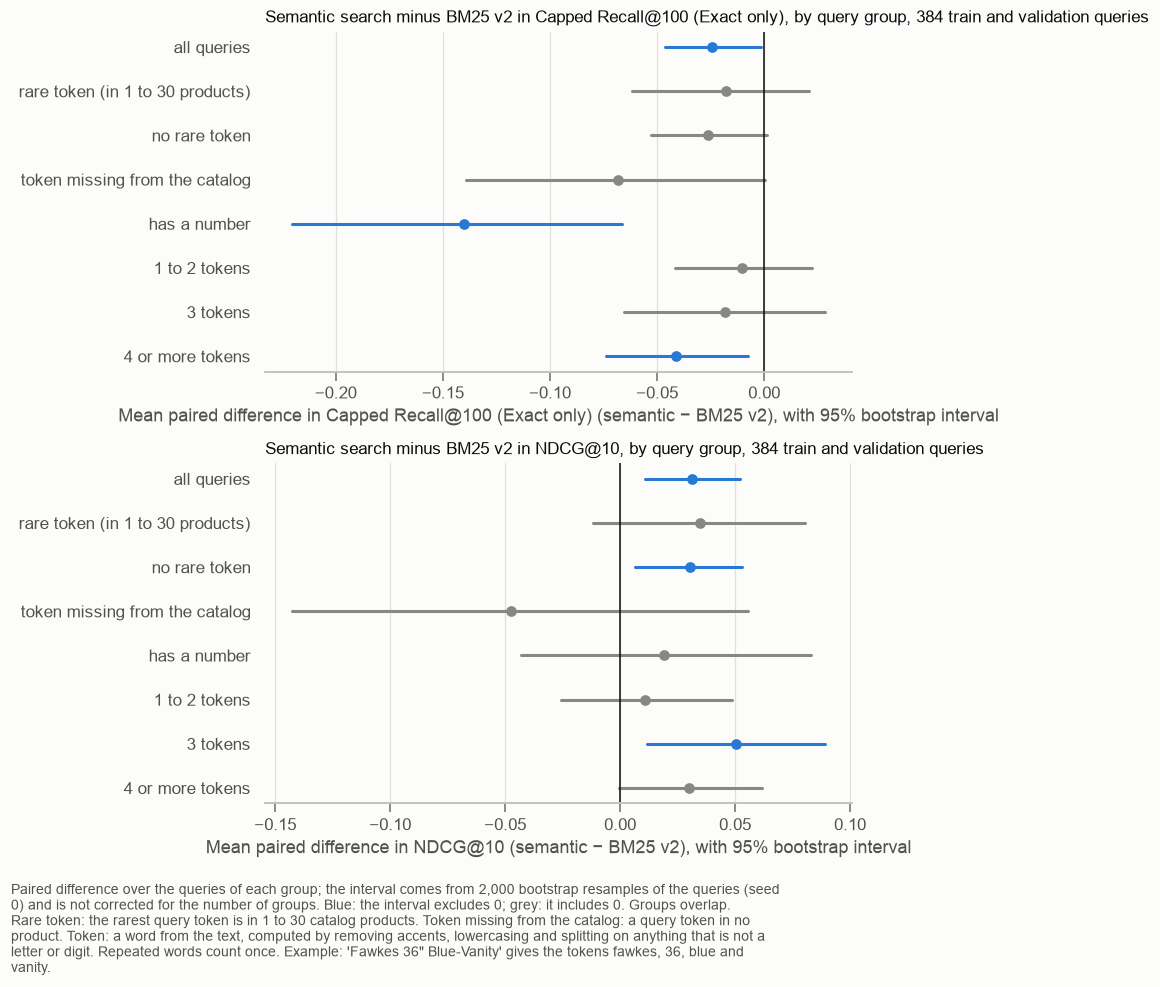

In [29]:
fig, axes = plt.subplots(2, 1, figsize=(8, 8))
for ax, metric, label in [(axes[0], "capped_recall@100", "Capped Recall@100 (Exact only)"), (axes[1], "ndcg@10", "NDCG@10")]:
    column = f"{metric}: semantic - BM25 v2"
    plots.difference_plot(ax, list(group_differences.index), group_differences[column],
                          group_differences[f"{column} low"], group_differences[f"{column} high"])
    ax.set_title(f"Semantic search minus BM25 v2 in {label}, by query group, 384 train and validation queries")
    ax.set_xlabel(f"Mean paired difference in {label} (semantic − BM25 v2), with 95% bootstrap interval")
fig.tight_layout()
plots.add_caption(fig, (
    "Paired difference over the queries of each group; the interval comes from 2,000 bootstrap resamples of the queries (seed 0) "
    "and is not corrected for the number of groups. Blue: the interval excludes 0; grey: it includes 0. Groups overlap. Rare token: "
    "the rarest query token is in 1 to 30 catalog products. Token missing from the catalog: a query token in no product. "
    + plots.TOKEN_DEFINITION
))
plt.show()

**Resultados**
- **Nas 384 queries, a BM25 v2 cobre mais e a semantic search ordena melhor:** contra a BM25 v2, a semantic search tem NDCG@10 +0,031 [0,011; 0,052] e Capped Recall@100 −0,024 [−0,046; −0,001], os dois intervalos excluindo 0.
- **A maior vantagem de cobertura da BM25 v2 está nas queries com número:** Capped Recall@100 de 0,844, contra 0,703 da semantic search (−0,140 [−0,220; −0,066]), em 29 queries. Também nas queries com 4 ou mais tokens (−0,041 [−0,074; −0,007]). Nas queries com token fora do catalog, a semantic search também fica abaixo (−0,068 [−0,139; 0,001]), com intervalo que toca 0.
- **Nas queries com rare token, os dois sistemas não se distinguem:** Capped Recall@100 −0,018 [−0,062; 0,021] e NDCG@10 +0,035 [−0,012; 0,080].
- **A hybrid search tem NDCG@10 maior que a BM25 v2 em todos os grupos,** com intervalo que exclui 0 em 7 dos 8 (a exceção são as 25 queries com token fora do catalog: +0,051 [−0,005; 0,114]).
- **Na cobertura, a hybrid search fica acima da BM25 v2 nas 384 queries** (+0,019 [0,008; 0,031]) e não se distingue dela nos grupos em que a BM25 v2 é mais forte: queries com número (0,826 contra 0,844; −0,018 [−0,047; 0,003]), com token fora do catalog e com 4 ou mais tokens.

**O que isso implica (nossa interpretação)**
- As queries justificam a BM25 como **componente de cobertura**, sobretudo quando a query tem números ou medidas, que o embedding não distingue bem. Não justificam a BM25 sozinha: a hybrid search mantém quase toda essa cobertura e ordena melhor.
- A suposição da Etapa 4.2, de que a BM25 ganha em nomes de produto e marcas, não se confirma em média: os exemplos daquela etapa (`trinaic`, `oller`) eram casos extremos.
- Juntando o train e o validation set, a vantagem de cobertura da hybrid search sobre a BM25 v2 tem intervalo que exclui 0; só no validation set (Etapa 6.1), com 77 queries, não tinha. Isso não muda nenhuma escolha: o train set foi usado para escolher os parâmetros dos três sistemas, então os valores dele são otimistas.

**Limitações**
- Os grupos foram definidos depois de ver os resultados, se sobrepõem, e alguns são pequenos (25 a 29 queries). O corte de rare token é arbitrário.
- Os intervalos não corrigem para 8 grupos × 2 métricas × 2 comparações.

**Hipóteses para a error analysis (não conferidas)**
- O embedding aproxima `46 inch` de outras medidas, porque números viram wordpieces sem relação de grandeza.
- Rare tokens de nomes de produto continuam funcionando na semantic search porque o mesmo nome aparece em `product_name` e se quebra nos mesmos wordpieces da query.

### 7.3 · Produtos sem `label` nos 100 primeiros

O Capped Recall@100 só conta produtos com `label` Exact. Se um sistema traz mais produtos sem `label` para os 100 primeiros, e parte deles for relevante, o Capped Recall@100 dele fica subestimado. Na Etapa 4.1, a semantic search tinha **mais** produtos com `label` nos 10 primeiros (judged@10); aqui medimos nos 100 primeiros (judged@100), por set.

In [30]:
judged_at_100 = pd.DataFrame({
    system: {
        set_name: np.nanmean([metrics.judged_at_k(analysis_runs[system][query_id], labels_by_query.get(query_id, {}), k=100)
                              for query_id in analysis_queries.index[analysis_queries["split"] == set_name] if analysis_runs[system][query_id]])
        for set_name in ["train", "validation"]
    }
    for system in analysis_systems
}).rename_axis("set")
plots.table(judged_at_100, "judged@100: share of the top 100 results that have a label for the query, by system and set",
            note="Queries with an empty result list are left out.", precision=3)

,BM25 v2,semantic,hybrid
set,,,
train,0.706,0.686,0.724
validation,0.676,0.627,0.669


**Resultados**
- **Nos 100 primeiros, a semantic search tem menos produtos com `label`:** judged@100 de 0,627 no validation set, contra 0,676 da BM25 v2 e 0,669 da hybrid search. No train set, 0,686, contra 0,706 e 0,724.
- É o contrário do que acontece nos 10 primeiros, em que a semantic search tem mais produtos com `label` (Etapa 4.1).

**O que isso implica (nossa interpretação)**
- Se parte dos produtos sem `label` nos 100 primeiros da semantic search for Exact, o Capped Recall@100 dela está subestimado em relação ao da BM25 v2. A hybrid search e a BM25 v2 têm judged@100 parecido, então a comparação entre as duas é menos afetada.

**Limitações**
- judged@100 não diz quantos produtos sem `label` são relevantes; só uma avaliação manual de uma amostra diria.

### 7.4 · As queries com a maior diferença de Capped Recall@100

As 8 queries em que a BM25 v2 mais ganha da semantic search em Capped Recall@100, e as 8 em que mais perde, com os descritores da Etapa 7.1 e o valor da hybrid search.

In [31]:
recall_by_query = pd.DataFrame({system: analysis_per_query[system]["capped_recall@100"] for system in analysis_systems}).dropna()
recall_by_query["semantic - BM25 v2"] = recall_by_query["semantic"] - recall_by_query["BM25 v2"]
recall_by_query = recall_by_query.join(analysis_queries[["query", "split"]]).join(query_descriptors)
print("queries with Exact:", len(recall_by_query), "| semantic better:", int((recall_by_query["semantic - BM25 v2"] > 0).sum()),
      "| BM25 v2 better:", int((recall_by_query["semantic - BM25 v2"] < 0).sum()),
      "| equal:", int((recall_by_query["semantic - BM25 v2"] == 0).sum()))
EXAMPLE_COLUMNS = ["query", "split", "BM25 v2", "semantic", "hybrid", "semantic - BM25 v2", "rarest_token_products", "has_unknown_token", "has_number"]
for title, rows in [("BM25 v2 gains the most", recall_by_query.nsmallest(8, "semantic - BM25 v2")),
                    ("the semantic search gains the most", recall_by_query.nlargest(8, "semantic - BM25 v2"))]:
    display(plots.table(rows[EXAMPLE_COLUMNS], f"Capped Recall@100 of each system: the 8 train and validation queries where {title}",
                        note="Capped Recall@100: Exact only. rarest_token_products: catalog products with the rarest query token. "
                             + plots.TOKEN_DEFINITION, precision=2))

queries with Exact: 304 | semantic better: 74 | BM25 v2 better: 114 | equal: 116


,query,split,BM25 v2,semantic,hybrid,semantic - BM25 v2,rarest_token_products,has_unknown_token,has_number
query_id,,,,,,,,,
21,living curtains pearl,train,1.00,0.00,1.00,-1.00,146,False,False
31,burnt orange curtains,train,1.00,0.00,1.00,-1.00,53,False,False
48,arwen table lamp,train,1.00,0.00,1.00,-1.00,4,False,False
76,46 inch closet door,validation,0.50,0.00,0.50,-0.50,148,False,True
292,decorative white pillow,validation,0.50,0.00,0.25,-0.50,"3,621",False,False
308,led 60,train,1.00,0.50,1.00,-0.50,"1,224",False,True
30,3 1/2 inch drawer pull,validation,0.85,0.38,0.61,-0.48,"1,899",False,True
314,body pillow and case,train,1.00,0.55,0.55,-0.45,498,False,False


,query,split,BM25 v2,semantic,hybrid,semantic - BM25 v2,rarest_token_products,has_unknown_token,has_number
query_id,,,,,,,,,
369,wrought tv stand,train,0.00,1.00,0.50,1.00,174,False,False
466,rock climbing wall kids,validation,0.00,1.00,0.00,1.00,101,False,False
129,wainscoting ideas,train,0.11,0.82,0.79,0.71,8,False,False
367,wooden chair outdoor,train,0.12,0.71,0.60,0.60,"1,504",False,False
202,full mattress padded liner,validation,0.16,0.73,0.56,0.58,319,False,False
278,parakeet toy,train,0.29,0.86,0.71,0.57,36,False,False
39,door jewelry organizer,train,0.48,0.81,0.68,0.32,258,False,False
138,glass doors for bath,train,0.63,0.92,0.80,0.29,"2,611",False,False


**Resultados**
- **Nas 304 queries com Exact, a BM25 v2 tem Capped Recall@100 maior em 114, a semantic search em 74, e há empate em 116.**
- **Entre as 8 maiores vantagens da BM25 v2,** três queries têm número (`46 inch closet door`, `led 60`, `3 1/2 inch drawer pull`) e três têm cor ou acabamento (`living curtains pearl`, `burnt orange curtains`, `decorative white pillow`). Em `living curtains pearl`, `burnt orange curtains` e `arwen table lamp`, a semantic search não traz nenhum Exact (0,00), e a BM25 v2 e a hybrid search trazem todos (1,00).
- **Entre as 8 maiores vantagens da semantic search,** a query descreve o produto com palavras diferentes das do catalog ou com variações: `wrought tv stand`, `wooden chair outdoor`, `wainscoting ideas`, `full mattress padded liner`, `parakeet toy`. A hybrid search fica entre os dois na maioria; em `rock climbing wall kids`, fica com 0,00, como a BM25 v2.

**Limitações**
- São os casos extremos, escolhidos pela maior diferença.

**Hipóteses para a error analysis (não conferidas)**
- Cores e acabamentos específicos (`pearl`, `burnt orange`) pesam pouco no embedding de um texto longo, em que a cor é uma palavra entre centenas.
- `wooden` contra `wood` e `wrought` contra `wrought iron` são variações que a remoção de plural da BM25 v2 não junta, e o embedding junta.